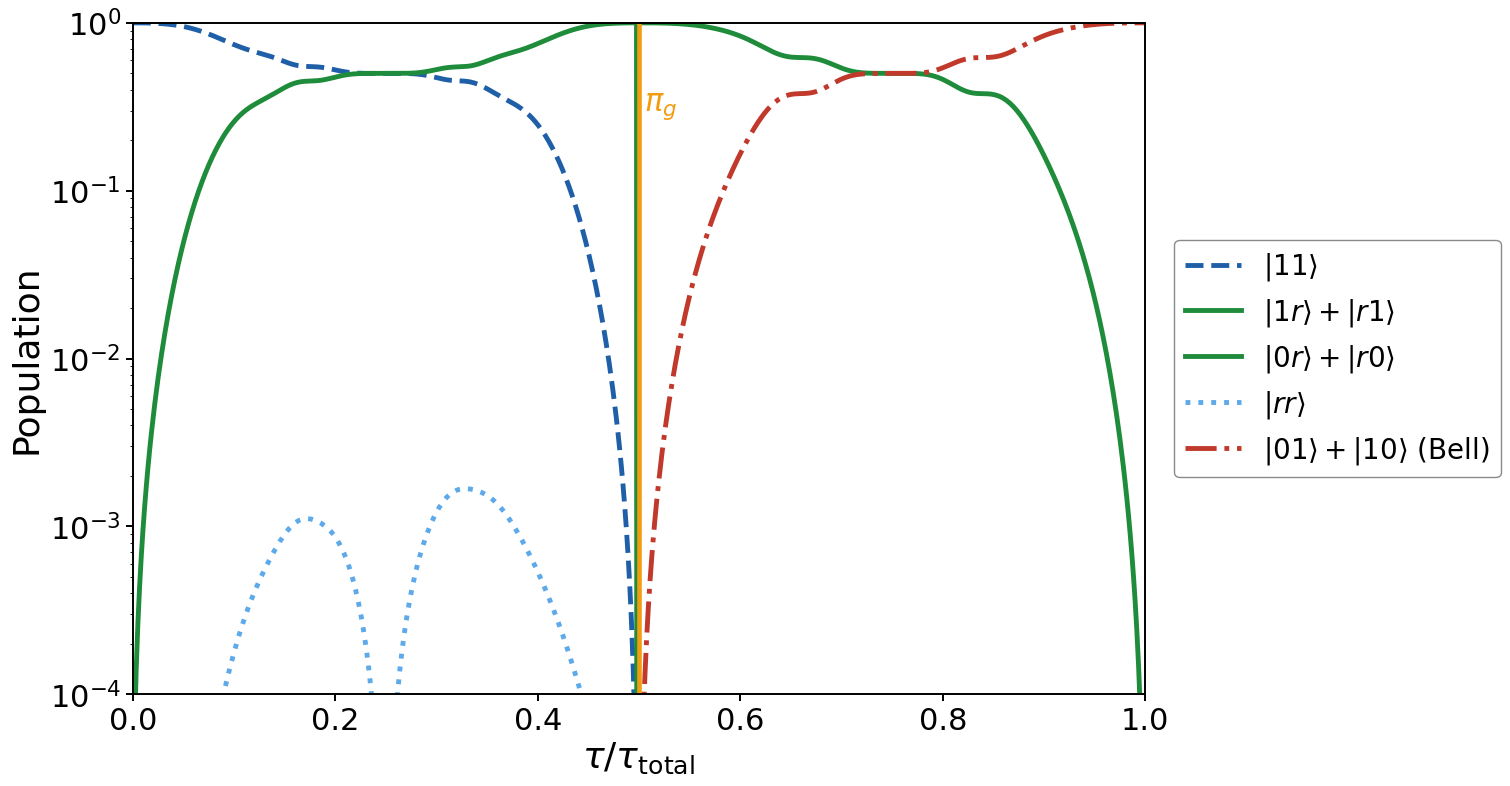

In [2]:
import numpy as np
from itertools import product
from scipy.linalg import eigh
import matplotlib.pyplot as plt
# ==================== 参数（全部无量纲，Omega0 = 2*pi*100 MHz 为能量/时间单位） ====================
OM1max = 0.2969771             # Omega_max / Omega0
DE1max = 0.1750508             # Delta_max / Omega0
V0     = 3.9167245             # 相互作用 / Omega0
sR     = 32.55720053835801     # Omega 包络宽度（无量纲）
sD     = 60.67294751009421     # Delta 包络宽度（无量纲）
tau_tot = 290.9825033647375    # 无量纲总时长
N_step = 600
pf     = 0.5
# ==================== 全 Hilbert 空间（2 原子，9 维） ====================
st = [''.join(p) for p in product('01r', repeat=2)]
ix = {s: i for i, s in enumerate(st)}
d = len(st)
C = np.zeros((d, d), dtype=complex)
for s, i in ix.items():
    for a in range(2):
        if s[a] == '1':
            s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r':
            s2 = s[:a]+'1'+s[a+1:]
        else:
            continue
        C[ix[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
E_i = np.array([V0*(s.count('r')*(s.count('r')-1)//2) for s in st], float)
g_perm = np.array([ix[s.replace('0','_').replace('1','0').replace('_','1')]
                    for s in st])
# ==================== 演化并记录布居（无耗散） ====================
psi = np.zeros(d, complex)
psi[ix['11']] = 1.0
t_pi = pf*tau_tot
dt = tau_tot/N_step
pops = np.zeros((N_step, d))
for n in range(N_step):
    t = (n+0.5)*dt
    tm = t_pi/2 if t < t_pi else t_pi + (tau_tot - t_pi)/2
    xR = (t-tm)/sR
    xD = (t-tm)/sD
    Om = -OM1max*np.sqrt(2*np.e)*xR*np.exp(-xR**2)
    De =  DE1max*np.e*xD**2*np.exp(-xD**2)
    w, v = eigh(Om*C + np.diag(De*n_r + E_i))
    psi = v @ (np.exp(-1j*w*dt)*(v.conj().T @ psi))
    if n == N_step//2 - 1:
        psi = psi[g_perm]
    pops[n] = np.abs(psi)**2
F = pops[-1, ix['01']] + pops[-1, ix['10']]
# ==================== 画图 ====================
BLUE   = '#1f5fa8'
GREEN  = '#1e8c3a'
LBLUE  = '#5da9e9'
RED    = '#c0392b'
ORANGE = '#f39c12'
LW = 3.5
tt = np.linspace(0, 1, N_step)
FS_LAB, FS_TCK, FS_TIT, FS_LEG = 26, 22, 22, 20
fig, ax = plt.subplots(figsize=(15, 8.5))
ax.plot(tt, pops[:, ix['11']], '--', color=BLUE,   lw=LW,
        label=r'$|11\rangle$')
ax.plot(tt, pops[:, ix['1r']]+pops[:, ix['r1']], '-', color=GREEN, lw=LW,
        label=r'$|1r\rangle+|r1\rangle$')
ax.plot(tt, pops[:, ix['0r']]+pops[:, ix['r0']], '-', color=GREEN, lw=LW,
        label=r'$|0r\rangle+|r0\rangle$')
ax.plot(tt, pops[:, ix['rr']], ':', color=LBLUE, lw=LW,
        label=r'$|rr\rangle$')
ax.plot(tt, pops[:, ix['01']]+pops[:, ix['10']], '-.', color=RED, lw=LW,
        label=r'$|01\rangle+|10\rangle$ (Bell)')
ax.axvline(0.5, color=ORANGE, lw=3.3)
ax.text(0.505, 0.3, r'$\pi_g$', color=ORANGE, fontsize=FS_TIT)
ax.set_xlim(0, 1)
ax.set_yscale('log')
ax.set_ylim(1e-4, 1)
ax.set_xlabel(r'$\tau/\tau_{\rm total}$', fontsize=FS_LAB)
ax.set_ylabel('Population', fontsize=FS_LAB)
ax.legend(fontsize=FS_LEG, loc='center left',
          bbox_to_anchor=(1.015, 0.5),
          framealpha=0.92, edgecolor='gray')
ax.tick_params(axis='both', which='major', labelsize=FS_TCK, width=1.4, length=5)
for sp in ax.spines.values():
    sp.set_linewidth(1.4)
plt.subplots_adjust(right=0.80, top=0.90)
plt.savefig('population演化_2比特_无量纲.png', dpi=200, bbox_inches='tight')
plt.show()

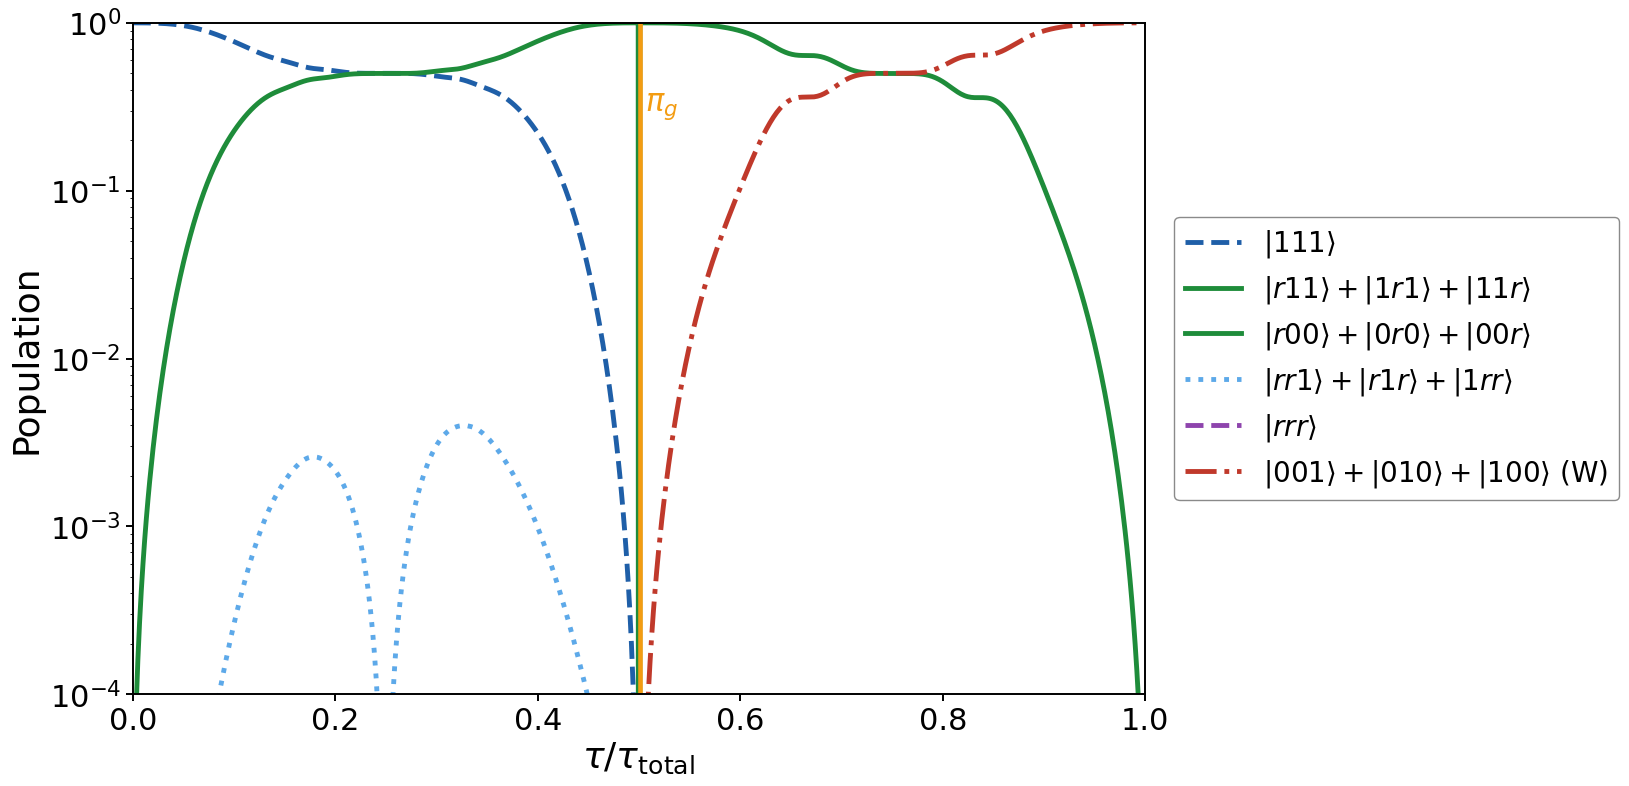

In [3]:
import numpy as np
from itertools import product
from scipy.linalg import eigh
import matplotlib.pyplot as plt

# ==================== 参数（全部无量纲，Omega0 = 2*pi*100 MHz 为能量/时间单位） ====================
TAU_TOT = 254.64804469273741   # 无量纲总时长
OM1max  = 0.356747            # Omega_max / Omega0
DE1max  = 0.22176485870975582 # Delta_max / Omega0
sR      = 27.050279329608937  # Omega 包络宽度（无量纲）
sD      = 47.3815270018622    # Delta 包络宽度（无量纲）
PF      = 0.501                # pi_g 位置
V0      = 4.319068724444445   # 相互作用 / Omega0
N_step  = 600

# ==================== 全 Hilbert 空间（3 原子，27 维） ====================
st = [''.join(p) for p in product('01r', repeat=3)]
ix = {s: i for i, s in enumerate(st)}
d = len(st)
C = np.zeros((d, d), dtype=complex)
for s, i in ix.items():
    for a in range(3):
        if s[a] == '1':
            s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r':
            s2 = s[:a]+'1'+s[a+1:]
        else:
            continue
        C[ix[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
E_i = np.array([V0*(s.count('r')*(s.count('r')-1)//2) for s in st], float)
g_perm = np.array([ix[s.replace('0','_').replace('1','0').replace('_','1')]
                   for s in st])

# ==================== 演化并记录布居（无耗散） ====================
psi = np.zeros(d, complex)
psi[ix['111']] = 1.0
t_pi = PF*TAU_TOT
dt = TAU_TOT/N_step
n_pi = int(round(PF*N_step))
pops = np.zeros((N_step, d))
for n in range(N_step):
    t = (n+0.5)*dt
    tm = t_pi/2 if t < t_pi else t_pi + (TAU_TOT - t_pi)/2
    xR = (t-tm)/sR
    xD = (t-tm)/sD
    Om = -OM1max*np.sqrt(2*np.e)*xR*np.exp(-xR**2)
    De =  DE1max*np.e*xD**2*np.exp(-xD**2)
    w, v = eigh(Om*C + np.diag(De*n_r + E_i))
    psi = v @ (np.exp(-1j*w*dt)*(v.conj().T @ psi))
    if n == n_pi - 1:                 # t = t_pi 处 pi_g
        psi = psi[g_perm]
    pops[n] = np.abs(psi)**2

F = pops[-1, ix['001']] + pops[-1, ix['010']] + pops[-1, ix['100']]


# ==================== 画图 ====================
BLUE='#1f5fa8'; GREEN='#1e8c3a'; LBLUE='#5da9e9'; RED='#c0392b'
ORANGE='#f39c12'; PURPLE='#8e44ad'
LW = 3.5
tt = np.linspace(0, 1, N_step)
FS_LAB, FS_TCK, FS_TIT, FS_LEG = 26, 22, 22, 20

fig, ax = plt.subplots(figsize=(15, 8.5))

ax.plot(tt, pops[:, ix['111']], '--', color=BLUE, lw=LW,
        label=r'$|111\rangle$')

ax.plot(tt, pops[:, ix['r11']]+pops[:, ix['1r1']]+pops[:, ix['11r']],
        '-', color=GREEN, lw=LW,
        label=r'$|r11\rangle+|1r1\rangle+|11r\rangle$')

ax.plot(tt, pops[:, ix['r00']]+pops[:, ix['0r0']]+pops[:, ix['00r']],
        '-', color=GREEN, lw=LW,
        label=r'$|r00\rangle+|0r0\rangle+|00r\rangle$')

ax.plot(tt, pops[:, ix['rr1']]+pops[:, ix['r1r']]+pops[:, ix['1rr']],
        ':', color=LBLUE, lw=LW,
        label=r'$|rr1\rangle+|r1r\rangle+|1rr\rangle$')

ax.plot(tt, pops[:, ix['rrr']], '--', color=PURPLE, lw=LW,
        label=r'$|rrr\rangle$')

ax.plot(tt, pops[:, ix['001']]+pops[:, ix['010']]+pops[:, ix['100']],
        '-.', color=RED, lw=LW,
        label=r'$|001\rangle+|010\rangle+|100\rangle$ (W)')

ax.axvline(PF, color=ORANGE, lw=3.3)
ax.text(PF+0.005, 0.3, r'$\pi_g$', color=ORANGE, fontsize=FS_TIT)

ax.set_xlim(0, 1)
ax.set_yscale('log')
ax.set_ylim(1e-4, 1)

ax.set_xlabel(r'$\tau/\tau_{\rm total}$', fontsize=FS_LAB)
ax.set_ylabel('Population', fontsize=FS_LAB)

ax.legend(fontsize=FS_LEG, loc='center left',
          bbox_to_anchor=(1.015, 0.5),
          framealpha=0.92, edgecolor='gray')

ax.tick_params(axis='both', which='major', labelsize=FS_TCK, width=1.4, length=5)
for sp in ax.spines.values():
    sp.set_linewidth(1.4)

plt.subplots_adjust(right=0.80, top=0.90)
plt.savefig('population演化_3比特_无量纲.png', dpi=200, bbox_inches='tight')
plt.show()

Final W4 fidelity = 0.9999973783
Final norm error  = 4.596e-14


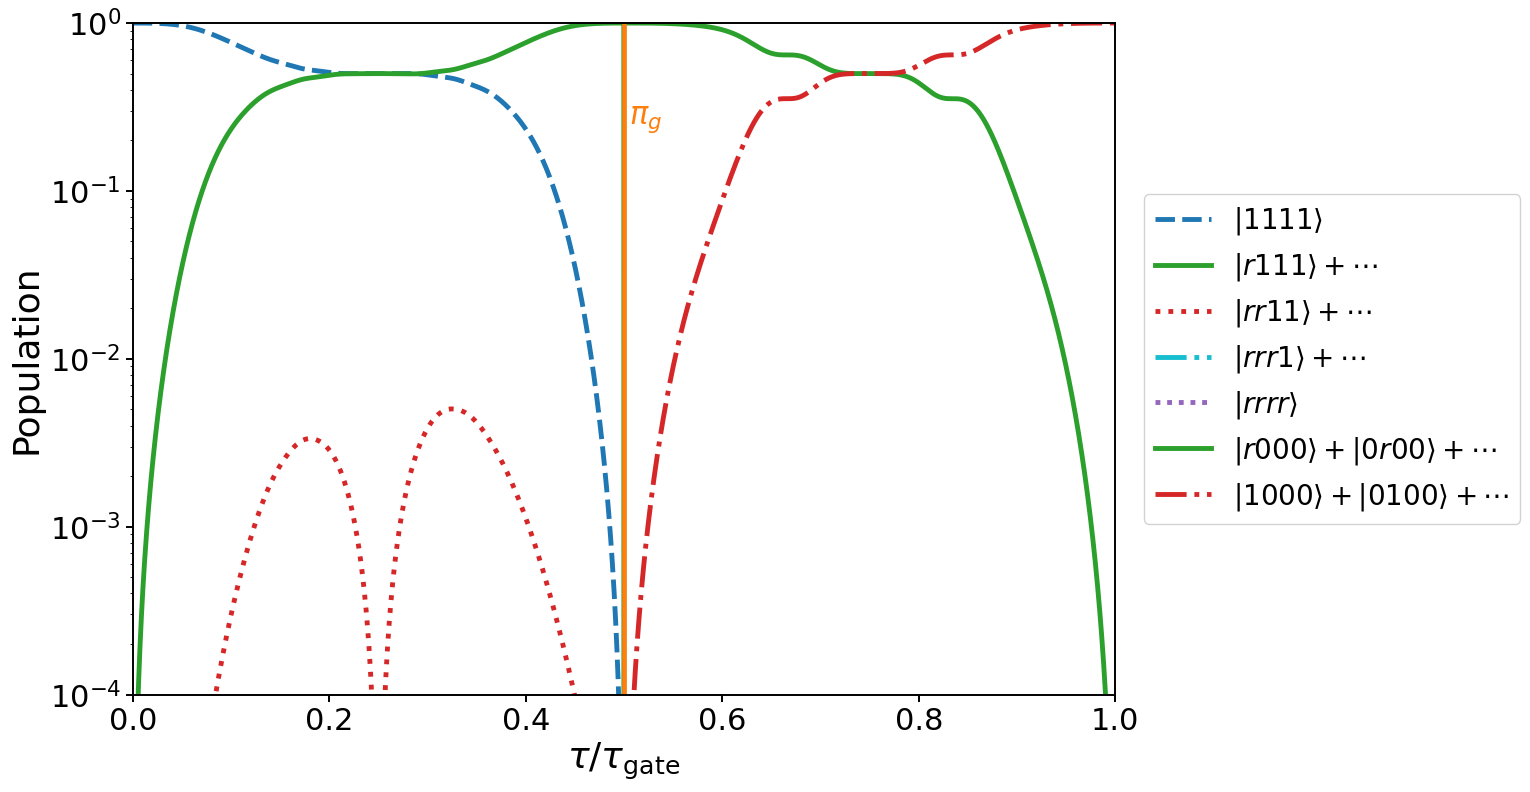

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from scipy.linalg import eigh

# ===================== Numerical settings =====================
TAU_TOT = 227.91
DT_TAU  = 0.05
N_STEPS = int(round(TAU_TOT / DT_TAU))

# ===================== Four-qubit tetrahedron (W-state preparation) =====================
states = [''.join(s) for s in product('01r', repeat=4)]
si = {s: i for i, s in enumerate(states)}
dim = len(states)
nr = np.array([s.count('r') for s in states], dtype=float)

pairs = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
interaction_count = np.zeros(dim)
for s, i in si.items():
    interaction_count[i] = sum(
        s[a] == 'r' and s[b] == 'r' for a, b in pairs
    )

C = np.zeros((dim, dim), dtype=complex)
for s, i in si.items():
    for atom in range(4):
        if s[atom] == '1':
            s2 = s[:atom] + 'r' + s[atom + 1:]
        elif s[atom] == 'r':
            s2 = s[:atom] + '1' + s[atom + 1:]
        else:
            continue
        C[si[s2], i] = 0.5

flip_map = np.array([
    si[s.replace('0', '_').replace('1', '0').replace('_', '1')]
    for s in states
])

# ===================== 脉冲与相互作用参数 =====================
OMMmax  = 0.4017
DE0max  = 0.2558
sR      = 23.76
sD      = 41.51
PF      = 0.5
V0      = 5.2799

def pulse(tau):
    tau = np.asarray(tau, float)
    tau_pi = PF * TAU_TOT
    tm = np.where(tau <= tau_pi, tau_pi / 2.0,
                  tau_pi + (TAU_TOT - tau_pi) / 2.0)
    xR = (tau - tm) / sR
    xD = (tau - tm) / sD
    Om = -np.sqrt(2.0 * np.e) * xR * np.exp(-xR ** 2)
    De = np.e * xD ** 2 * np.exp(-xD ** 2)
    return Om, De

# ===================== 无耗散幺正演化 =====================
psi = np.zeros(dim, dtype=complex)
psi[si['1111']] = 1.0

times = np.linspace(0.0, TAU_TOT, N_STEPS + 1)
pops = np.zeros((N_STEPS + 1, dim))
pops[0] = np.abs(psi) ** 2

dt = TAU_TOT / N_STEPS
n_half = int(round(PF * TAU_TOT / DT_TAU))

for step in range(N_STEPS):
    if step == n_half:
        psi = psi[flip_map]
        pops[step] = np.abs(psi) ** 2

    t_mid = (step + 0.5) * dt
    om_norm, de_norm = pulse(t_mid)
    H = om_norm * OMMmax * C + np.diag(
        de_norm * DE0max * nr + V0 * interaction_count
    )

    eigenvalues, eigenvectors = eigh(H)
    psi = eigenvectors @ (
        np.exp(-1j * eigenvalues * dt) * (eigenvectors.conj().T @ psi)
    )
    pops[step + 1] = np.abs(psi) ** 2

w_states = ['1000', '0100', '0010', '0001']
psi_w = np.zeros(dim, dtype=complex)
for s in w_states:
    psi_w[si[s]] = 0.5
fidelity = abs(np.vdot(psi_w, psi)) ** 2
norm_error = abs(np.vdot(psi, psi).real - 1.0)

print(f'Final W4 fidelity = {fidelity:.10f}')
print(f'Final norm error  = {norm_error:.3e}')

# ===================== 布居分组 =====================
def population_of(names):
    return pops[:, [si[s] for s in names]].sum(axis=1)

single_r_before = [
    s for s in states if set(s) <= {'1', 'r'} and s.count('r') == 1
]
double_r_before = [
    s for s in states if set(s) <= {'1', 'r'} and s.count('r') == 2
]
triple_r_before = [
    s for s in states if set(s) <= {'1', 'r'} and s.count('r') == 3
]

p_1111 = pops[:, si['1111']]
p_1r_before = population_of(single_r_before)
p_2r_before = population_of(double_r_before)
p_3r_before = population_of(triple_r_before)
p_4r_before = pops[:, si['rrrr']]
p_r000 = population_of(['r000', '0r00', '00r0', '000r'])
p_w = population_of(w_states)

# ===================== 绘图 =====================
x = times / TAU_TOT
left = slice(0, n_half + 1)
right = slice(n_half, N_STEPS + 1)

# 配色顺序（从上到下）：蓝、绿、红、青、紫、绿、红
blue   = '#1f77b4'
green  = '#2ca02c'
red    = '#d62728'
cyan   = '#17becf'
purple = '#9467bd'
orange = '#ff7f0e'

LW = 3.5
FS_LAB, FS_TCK, FS_TIT, FS_LEG = 26, 22, 22, 20

fig, ax = plt.subplots(figsize=(15, 8.5))

h_left = [
    ax.plot(x[left], np.clip(p_1111[left], 1e-12, None),
            color=blue, ls=(0, (4, 1.5)), lw=LW,
            label=r'$|1111\rangle$')[0],
    ax.plot(x[left], np.clip(p_1r_before[left], 1e-12, None),
            color=green, ls='-', lw=LW,
            label=r'$|r111\rangle+\cdots$')[0],
    ax.plot(x[left], np.clip(p_2r_before[left], 1e-12, None),
            color=red, ls=':', lw=LW,
            label=(r'$|rr11\rangle+\cdots$'))[0],
    ax.plot(x[left], np.clip(p_3r_before[left], 1e-12, None),
            color=cyan, ls='-.', lw=LW,
            label=r'$|rrr1\rangle+\cdots$')[0],
    ax.plot(x[left], np.clip(p_4r_before[left], 1e-12, None),
            color=purple, ls=(0, (1, 1.4)), lw=LW,
            label=r'$|rrrr\rangle$')[0],
]

h_right = [
    ax.plot(x[right], np.clip(p_r000[right], 1e-12, None),
            color=green, ls='-', lw=LW,
            label=r'$|r000\rangle+|0r00\rangle+\cdots$')[0],
    ax.plot(x[right], np.clip(p_w[right], 1e-12, None),
            color=red, ls='-.', lw=LW,
            label=r'$|1000\rangle+|0100\rangle+\cdots$')[0],
]

ax.axvline(PF, color=orange, lw=3.3)
ax.text(PF + 0.005, 0.25, r'$\pi_g$', color=orange, fontsize=FS_TIT)
ax.set_xlim(0.0, 1.0)
ax.set_yscale('log')
ax.set_ylim(1e-4, 1.0)
ax.set_xlabel(r'$\tau/\tau_{\mathrm{gate}}$', fontsize=FS_LAB)
ax.set_ylabel('Population', fontsize=FS_LAB)

ax.tick_params(axis='both', labelsize=FS_TCK, width=1.4, length=5)
for spine in ax.spines.values():
    spine.set_linewidth(1.4)

ax.legend(handles=h_left + h_right, fontsize=FS_LEG, loc='center left',
          bbox_to_anchor=(1.015, 0.5), framealpha=0.88)

plt.subplots_adjust(right=0.78, top=0.90)
plt.show()

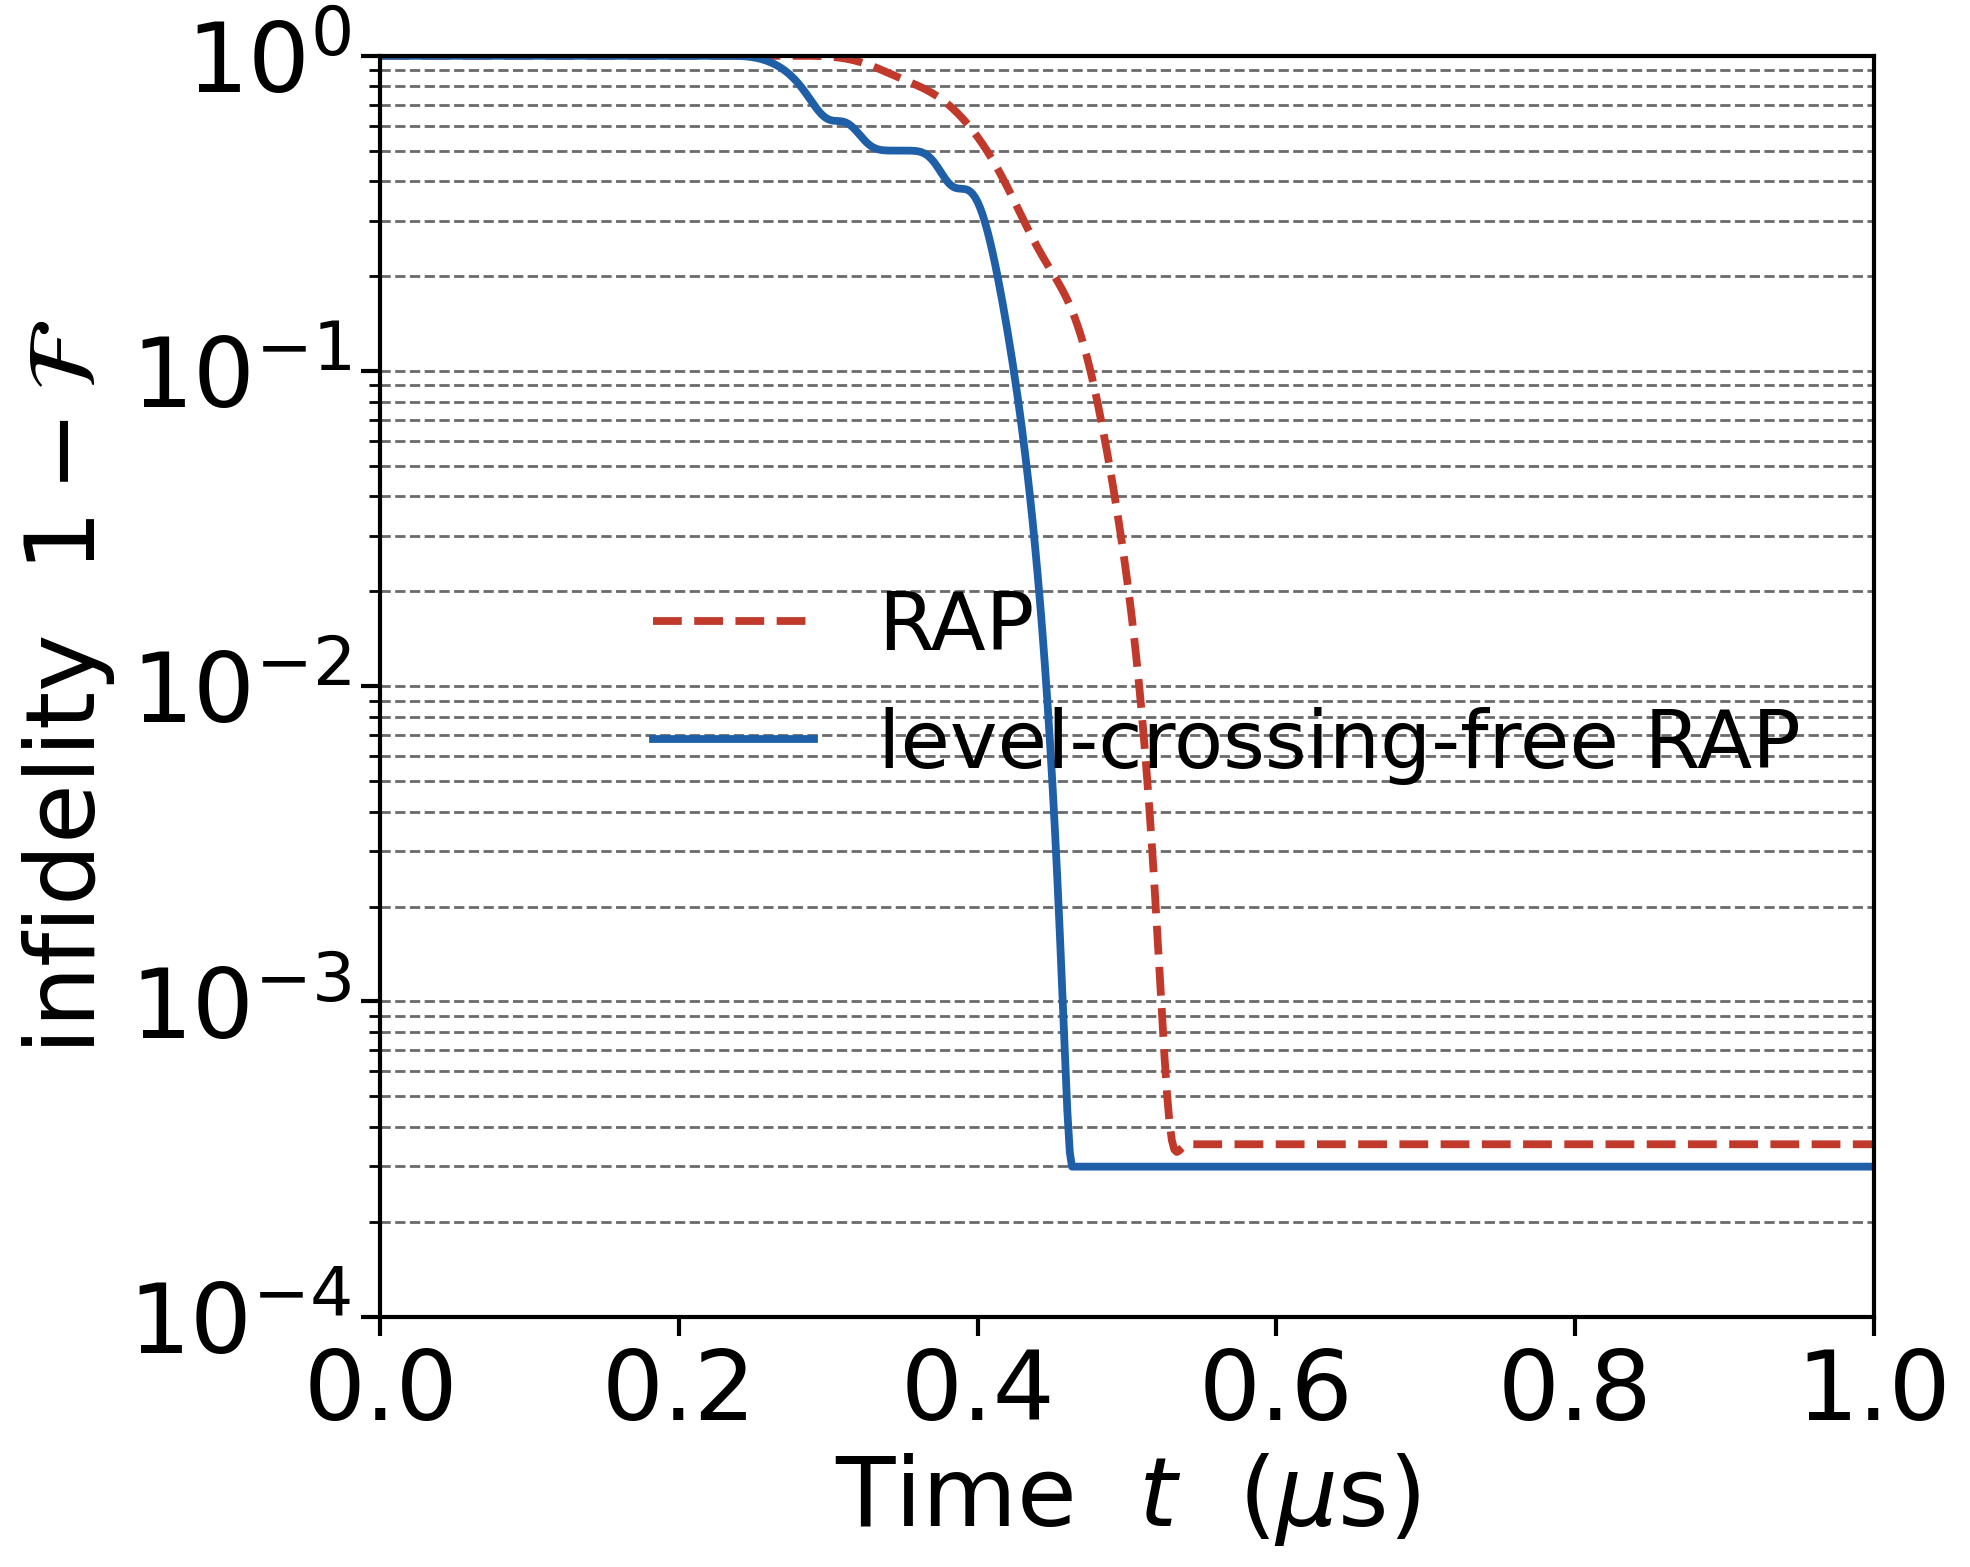

In [1]:
# ============================================================
# Cell 1：放在最前面
# ============================================================
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
from itertools import product as iproduct
import scipy.sparse as sp
from scipy.integrate import solve_ivp
import os
import sys
import matplotlib
import matplotlib.pyplot as plt   # ← 直接用默认后端，删掉了 _pick_backend


SQRT2E = np.sqrt(2 * np.e)
T_END = 1.0                       # us，总观察时长
NPT = 601

# =====================================================================
# 1. 基矢与算符
# =====================================================================
def build_system(n, Vmat):
    states = [''.join(p) for p in iproduct('01r', repeat=n)]
    idx = {s: i for i, s in enumerate(states)}
    dim = 3 ** n
    I3 = sp.identity(3, format='csr', dtype=complex)
    Pr = sp.csr_matrix(np.diag([0., 0., 1.]).astype(complex))
    R1 = sp.csr_matrix(np.array([[0, 0, 0], [0, 0, 0], [0, 1, 0]], dtype=complex))
    J0 = sp.csr_matrix(np.array([[0, 0, 1], [0, 0, 0], [0, 0, 0]], dtype=complex))
    J1 = sp.csr_matrix(np.array([[0, 0, 0], [0, 0, 1], [0, 0, 0]], dtype=complex))
    def embed(A, i):
        out = sp.identity(1, format='csr', dtype=complex)
        for k in range(n):
            out = sp.kron(out, A if k == i else I3, format='csr')
        return out
    Nr = sp.csr_matrix((dim, dim), dtype=complex)
    C = sp.csr_matrix((dim, dim), dtype=complex)
    jumps = []
    for i in range(n):
        Nr = Nr + embed(Pr, i)
        Ri = embed(R1, i)
        C = C + Ri + Ri.T
        jumps += [embed(J0, i), embed(J1, i), embed(Pr, i)]
    Vd = np.array([sum(Vmat[i][j] for i in range(n) for j in range(i + 1, n)
                       if s[i] == 'r' and s[j] == 'r') for s in states])
    perm = np.array([idx[s.translate(str.maketrans('01', '10'))] for s in states])
    return states, idx, dim, Nr, C, sp.diags(Vd), jumps, perm

def liouvillian_diss(jumps, rates, dim, dump=False):
    I = sp.identity(dim, format='csr', dtype=complex)
    L = sp.csr_matrix((dim * dim, dim * dim), dtype=complex)
    for Lk, g in zip(jumps, rates):
        LdL = (Lk.conjugate().T @ Lk).tocsr()
        if dump:
            L = L - 0.5 * g * sp.kron(I, LdL, format='csr') \
                - 0.5 * g * sp.kron(LdL.T, I, format='csr')
        else:
            Lc = Lk.copy(); Lc.data = Lc.data.conjugate()
            L = L + g * (sp.kron(Lc, Lk, format='csr')
                         - 0.5 * sp.kron(I, LdL, format='csr')
                         - 0.5 * sp.kron(LdL.T, I, format='csr'))
    return L

def lindblad_rhs_dense(rho, H, L_ops_dense, L_rates):
    """完整 Lindblad 主方程（稠密矩阵版）。"""
    dr = -1j * (H @ rho - rho @ H)
    for Lk, g in zip(L_ops_dense, L_rates):
        LdL = Lk.conj().T @ Lk
        dr = dr + g * (Lk @ rho @ Lk.conj().T
                       - 0.5 * (LdL @ rho + rho @ LdL))
    return dr

# =====================================================================
# 2. 两套脉冲
# =====================================================================
def pulse_rap(tau_tot, om_max, del_max, fR=0.175, fD=0.5):
    tauR, tauD = fR * tau_tot, fD * tau_tot
    a = np.exp(-(tau_tot / (4 * tauR)) ** 4)
    def f(tau):
        k = 1 if tau < tau_tot / 2 else 2
        tk = (2 * k - 1) * tau_tot / 4
        Om = om_max * (np.exp(-((tau - tk) / tauR) ** 4) - a) / (1 - a)
        De = (-1) ** (k + 1) * del_max * np.sin(np.pi * (tau - tk) / tauD)
        return Om, De
    return f

def pulse_opt(tau_tot, om_max, del_max, sR, sD, pf=0.5):
    tpi = pf * tau_tot
    def f(tau):
        tm = tpi / 2 if tau < tpi else tpi + (tau_tot - tpi) / 2
        xR = (tau - tm) / sR
        xD = (tau - tm) / sD
        Om = -om_max * SQRT2E * xR * np.exp(-xR ** 2)
        De = del_max * np.e * xD ** 2 * np.exp(-xD ** 2)
        return Om, De
    return f

# =====================================================================
# 3. 构型
# =====================================================================
def Vfull(n, V0):
    return [[V0 if i != j else 0.0 for j in range(n)] for i in range(n)]

def Vsquare(V_adj, V_diag):
    M = [[0.0] * 4 for _ in range(4)]
    for i, j in [(0, 1), (1, 2), (2, 3), (3, 0)]:
        M[i][j] = M[j][i] = V_adj
    for i, j in [(0, 2), (1, 3)]:
        M[i][j] = M[j][i] = V_diag
    return M

GAMMA_CS = 1 / 540.0
GAMMA_RB = 1 / 147.0
_R2Q, _R3Q = 0.70 / 0.17, 0.73 / 0.17
_RG = 4.85
_TAU_G = 340.0 * (1.13 / 4.85)

CASES = {
    'RAP-2q': dict(n=2, family='RAP', V=Vfull(2, 0.70), tau_tot=340.0,
                   om_max=0.17, del_max=0.24, gamma_r=GAMMA_CS,
                   init='11', target=[('10', 1), ('01', 1)],
                   R_ref=2 * np.pi * 100.0),
    # OPT 即无能级交叉脉冲；参数与 2 比特鲁棒性程序完全一致
    'OPT-2q': dict(n=2, family='OPT', V=Vfull(2, 3.9167245), tau_tot=290.9825033647375,
                   om_max=0.2969771, del_max=0.1750508, sR=32.55720053835801,
                   sD=60.67294751009421, pf=0.5,
                   gamma_r=GAMMA_CS, init='11', target=[('10', 1), ('01', 1)],
                   R_ref=2 * np.pi * 100.0),
}

def trajectory(cfg, R, rtol=1e-9, atol=1e-11):
    n = cfg['n']
    states, idx, dim, Nr, C, Vs, jumps, perm = build_system(n, cfg['V'])
    tau_tot = cfg['tau_tot']
    gam = cfg['gamma_r'] / R
    Ld = liouvillian_diss(jumps, [gam / 16, gam / 16, 7 * gam / 8] * n,
                          dim, dump=cfg.get('dump', False))
    L_ops_dense = [Lk.toarray().astype(complex) for Lk in jumps]
    L_rates = [gam / 16, gam / 16, 7 * gam / 8] * n
    f = (pulse_rap(tau_tot, cfg['om_max'], cfg['del_max'])
         if cfg['family'] == 'RAP' else
         pulse_opt(tau_tot, cfg['om_max'], cfg['del_max'],
                   cfg['sR'], cfg['sD'], cfg.get('pf', 0.5)))
    def rhs_drive(tau, y):
        rho = y.reshape((dim, dim), order='F')
        Om, De = f(tau)
        H = De * Nr + 0.5 * Om * C + Vs
        dr = lindblad_rhs_dense(rho, H, L_ops_dense, L_rates)
        return dr.reshape(-1, order='F')
    def rhs_free(tau, y):
        rho = y.reshape((dim, dim), order='F')
        H = Vs
        dr = lindblad_rhs_dense(rho, H, L_ops_dense, L_rates)
        return dr.reshape(-1, order='F')
    psi0 = np.zeros(dim, complex); psi0[idx[cfg['init']]] = 1.0
    y0 = np.outer(psi0, psi0.conj()).reshape(-1, order='F')
    t_gate = tau_tot / R
    t_phys = np.linspace(0, T_END, NPT)
    tau_all = R * t_phys
    half, end = tau_tot / 2, tau_tot
    tau_free_end = R * T_END
    m1 = tau_all <= half
    te1 = np.unique(np.append(tau_all[m1], half))
    s1 = solve_ivp(rhs_drive, (0, half), y0, method='DOP853',
                   rtol=rtol, atol=atol, t_eval=te1)
    rmid = s1.y[:, -1].reshape((dim, dim), order='F')[np.ix_(perm, perm)]
    y1 = rmid.reshape(-1, order='F')
    m2 = (tau_all > half) & (tau_all <= end)
    te2 = np.unique(np.append(tau_all[m2], end))
    s2 = solve_ivp(rhs_drive, (half, end), y1, method='DOP853',
                   rtol=rtol, atol=atol, t_eval=te2)
    m3 = tau_all > end
    te3 = np.unique(np.append(tau_all[m3], tau_free_end))
    s3 = solve_ivp(rhs_free, (end, tau_free_end), s2.y[:, -1],
                   method='DOP853', rtol=rtol, atol=atol, t_eval=te3)
    TAU = np.concatenate([s1.t, s2.t[1:], s3.t[1:]])
    Y = np.hstack([s1.y, s2.y[:, 1:], s3.y[:, 1:]])
    tv = np.zeros(dim, complex)
    for s_, amp in cfg['target']:
        tv[idx[s_]] += amp
    tv /= np.linalg.norm(tv)
    infid = np.array([1.0 - float(np.real(tv.conj()
                        @ Y[:, m].reshape((dim, dim), order='F')
                        @ tv)) for m in range(Y.shape[1])])
    Pr = np.zeros(dim)
    Pr[[idx[s_] for s_ in states if 'r' in s_]] = 1.0
    rho_end = s2.y[:, -1].reshape((dim, dim), order='F')
    r_pop = float(np.real(np.trace(rho_end @ np.diag(Pr))))
    return TAU / R, infid, t_gate, r_pop

# =====================================================================
# 5. 主程序
# =====================================================================
if __name__ == '__main__':
    res = {}
    for key in ['RAP-2q', 'OPT-2q']:
        cfg = CASES[key]
        R = cfg['R_ref']
        t, inf, tg, rp = trajectory(cfg, R)
        res[key] = (t, inf, tg)
        i_gate = int(np.argmin(np.abs(t - tg)))
        i_end = int(np.argmin(np.abs(t - T_END)))

    # ★ 样式：全部实线；红 = RAP，蓝 = our work
    LC = {'RAP': '#c0392b', 'OPT': '#1f5fa8'}
    LABEL = {'RAP': 'RAP', 'OPT': 'level-crossing-free RAP'}
    LS = {'RAP': '--', 'OPT': '-'}
    FS_LAB, FS_TCK, FS_TIT = 35, 35, 35
    fig, ax = plt.subplots(figsize=(10.0, 8.0))
    for key in ['RAP-2q', 'OPT-2q']:
        t, inf, tg = res[key]
        fam = key[:3]
        ax.plot(t, inf, LS[fam], color=LC[fam], lw=2.8, label=LABEL[fam])
    ax.set_yscale('log')
    ax.set_xlim(0, T_END)
    ax.set_ylim(1e-4, 1e0)
    YTICKS = [1e0, 1e-1, 1e-2, 1e-3, 1e-4]
    ax.set_yticks(YTICKS)
    for yv in YTICKS:
        ax.axhline(yv, color='0.1', lw=1.0, ls='--', alpha=.65, zorder=0)
    SUB = np.array([2, 3, 4, 5, 6, 7, 8, 9], dtype=float)
    for yv in YTICKS[:-1]:
        for s in SUB:
            ax.axhline(yv * s / 10.0, color='0.1', lw=1.0, ls='--', alpha=.65, zorder=0)
    ax.set_xlabel(r'Time  $t$  ($\mu$s)', fontsize=FS_LAB)
    ax.set_ylabel(r'infidelity  $1-\mathcal{F}$', fontsize=FS_LAB)
    ax.tick_params(axis='both', which='major',
                   labelsize=FS_TCK, width=1.5, length=7)
    ax.tick_params(axis='both', which='minor', width=1.0, length=4)
    leg = ax.legend(fontsize=FS_TCK - 6, loc='best', frameon=False)
    for sp_ in ax.spines.values():
        sp_.set_linewidth(1.5)
    plt.tight_layout()
    plt.savefig('free_evol_2qubit_style.png', dpi=170)


图片已存为 free_evol_3qubit_style.png


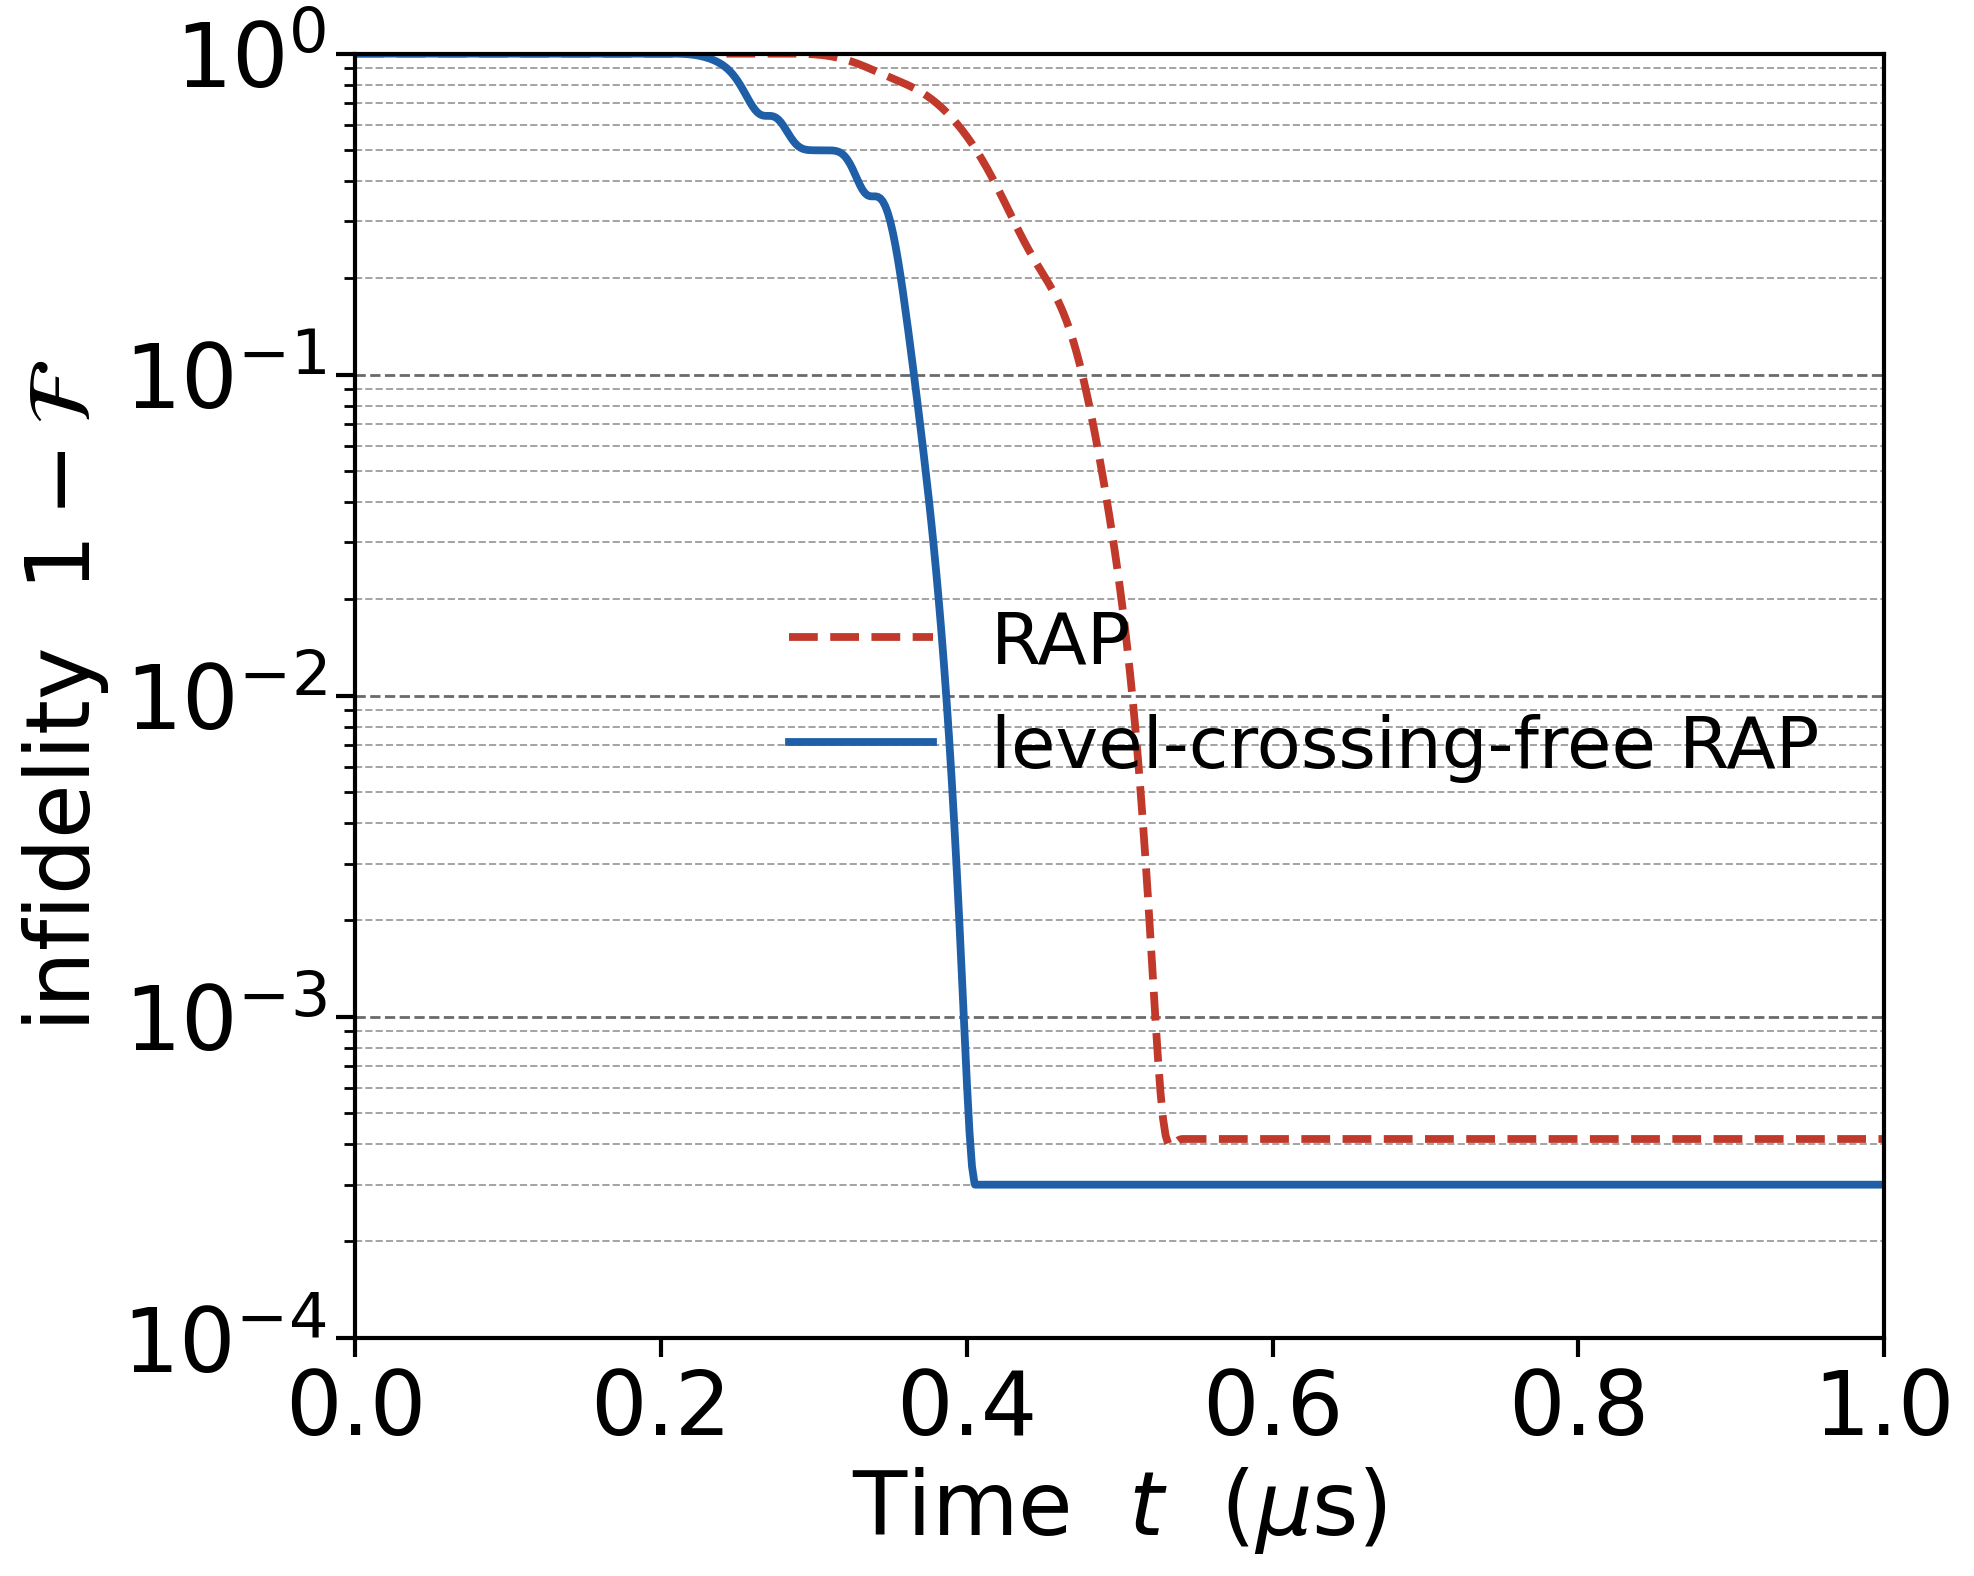

In [2]:
# ============================================================
# Cell 1：放在最前面
# ============================================================
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
from itertools import product as iproduct
import scipy.sparse as sp
from scipy.integrate import solve_ivp
import matplotlib
import matplotlib.pyplot as plt

SQRT2E = np.sqrt(2 * np.e)
T_END = 1.0                       # us，总观察时长
NPT = 601

# ==================== 基矢与算符 ====================
def build_system(n, Vmat):
    states = [''.join(p) for p in iproduct('01r', repeat=n)]
    idx = {s: i for i, s in enumerate(states)}
    dim = 3 ** n
    I3 = sp.identity(3, format='csr', dtype=complex)
    Pr = sp.csr_matrix(np.diag([0., 0., 1.]).astype(complex))
    R1 = sp.csr_matrix(np.array([[0, 0, 0], [0, 0, 0], [0, 1, 0]], dtype=complex))
    J0 = sp.csr_matrix(np.array([[0, 0, 1], [0, 0, 0], [0, 0, 0]], dtype=complex))
    J1 = sp.csr_matrix(np.array([[0, 0, 0], [0, 0, 1], [0, 0, 0]], dtype=complex))
    def embed(A, i):
        out = sp.identity(1, format='csr', dtype=complex)
        for k in range(n):
            out = sp.kron(out, A if k == i else I3, format='csr')
        return out
    Nr = sp.csr_matrix((dim, dim), dtype=complex)
    C  = sp.csr_matrix((dim, dim), dtype=complex)
    jumps = []
    for i in range(n):
        Nr = Nr + embed(Pr, i)
        Ri = embed(R1, i)
        C = C + Ri + Ri.T
        jumps += [embed(J0, i), embed(J1, i), embed(Pr, i)]
    Vd = np.array([sum(Vmat[i][j] for i in range(n) for j in range(i + 1, n)
                      if s[i] == 'r' and s[j] == 'r') for s in states])
    perm = np.array([idx[s.translate(str.maketrans('01', '10'))] for s in states])
    return states, idx, dim, Nr, C, sp.diags(Vd), jumps, perm

def build_L_ops_dense(dim, states, idx, n, rates):
    """构造稠密跳跃算符 L_ops（完整 Lindblad 用）。
    rates = (gamma_spont_0, gamma_spont_1, gamma_deph) 每原子，长度 3"""
    g0, g1, gd = rates
    L_ops = []
    for a in range(n):
        for ch, g in (('0', g0), ('1', g1)):
            L = np.zeros((dim, dim), dtype=complex)
            for s, i in idx.items():
                if s[a] == 'r':
                    L[idx[s[:a]+ch+s[a+1:]], i] = np.sqrt(g)
            L_ops.append(L)
    for a in range(n):
        diag = np.array([1.0 if s[a] == 'r' else 0.0 for s in states], dtype=float)
        L_ops.append(np.sqrt(gd) * np.diag(diag))
    return L_ops

# ==================== 脉冲 ====================
def pulse_rap(tau_tot, om_max, del_max, fR=0.175, fD=0.5):
    tauR, tauD = fR * tau_tot, fD * tau_tot
    a = np.exp(-(tau_tot / (4 * tauR)) ** 4)
    def f(tau):
        k = 1 if tau < tau_tot / 2 else 2
        tk = (2 * k - 1) * tau_tot / 4
        Om = om_max * (np.exp(-((tau - tk) / tauR) ** 4) - a) / (1 - a)
        De = (-1) ** (k + 1) * del_max * np.sin(np.pi * (tau - tk) / tauD)
        return Om, De
    return f

def pulse_opt(tau_tot, om_max, del_max, sR, sD, pf=0.5):
    tpi = pf * tau_tot
    def f(tau):
        tm = tpi / 2 if tau < tpi else tpi + (tau_tot - tpi) / 2
        xR = (tau - tm) / sR
        xD = (tau - tm) / sD
        Om = -om_max * SQRT2E * xR * np.exp(-xR ** 2)
        De = del_max * np.e * xD ** 2 * np.exp(-xD ** 2)
        return Om, De
    return f

# ==================== 构型 ====================
def Vfull(n, V0):
    return [[V0 if i != j else 0.0 for j in range(n)] for i in range(n)]

def Vsquare(V_adj, V_diag):
    M = [[0.0] * 4 for _ in range(4)]
    for i, j in [(0, 1), (1, 2), (2, 3), (3, 0)]:
        M[i][j] = M[j][i] = V_adj
    for i, j in [(0, 2), (1, 3)]:
        M[i][j] = M[j][i] = V_diag
    return M

GAMMA_CS = 1 / 540.0
GAMMA_RB = 1 / 147.0
OMEGA10 = 2 * np.pi * 100.0      # Ω10 = 2π×100 MHz（鲁棒性程序口径）
OMEGA0 = OMEGA10                 # 别名，供 OPT 分支 R_ref 使用

# ==================== RAP 参数（原始值，保持不变） ====================
TAU_TOT_RAP = 340.0 * 0.17
OM1max_RAP  = 1.0
DE1max_RAP  = 0.24 / 0.17
V0_RAP      = 0.73 / 0.17
OMEGA0_RAP  = 2 * np.pi * 17.0   # RAP 自己的频率参考（Ω0 = 2π×17 MHz）

# ==================== OPT 参数（与 3比特鲁棒性新参数.txt 完全一致） ====================
TAU_TOT = 254.64804469273741     # 无量纲总时长 → t_tot = TAU_TOT/Ω10 µs
OM1max  = 0.356747              # Ωmax (Ω10 单位)
DE1max  = 0.22176485870975582   # Δ0 峰值 (Ω10 单位)
sR      = 27.050279329608937    # Ω 包络宽度 (无量纲)
sD      = 47.3815270018622      # Δ 包络宽度 (无量纲)
PF      = 0.501                 # πg 位置 (t_π = PF·tau_tot)
V0      = 4.319068724444445     # 相互作用 (Ω10 单位, 阻塞几何)

CASES = {
    'RAP-3q': dict(n=3, family='RAP', V=Vfull(3, V0_RAP), tau_tot=TAU_TOT_RAP,
                   om_max=OM1max_RAP, del_max=DE1max_RAP, gamma_r=GAMMA_CS,
                   init='111', target=[('001',1),('010',1),('100',1)],
                   R_ref=OMEGA0_RAP),
    'OPT-3q': dict(n=3, family='OPT', V=Vfull(3, V0), tau_tot=TAU_TOT,
                   om_max=OM1max, del_max=DE1max, sR=sR, sD=sD, pf=PF,
                   gamma_r=GAMMA_CS, init='111',
                   target=[('001',1),('010',1),('100',1)],
                   R_ref=OMEGA10),
}

# ==================== 门  ====================
def trajectory(cfg, R, rtol=1e-9, atol=1e-11):
    n = cfg['n']
    states, idx, dim, Nr, C, Vs, jumps, perm = build_system(n, cfg['V'])
    tau_tot = cfg['tau_tot']
    gam = cfg['gamma_r'] / R
    gamma_spont = gam / 16.0
    gamma_deph  = 7.0 * gam / 8.0
    rates = (gamma_spont, gamma_spont, gamma_deph)
    L_ops = build_L_ops_dense(dim, states, idx, n, rates)
    LdL_list = [L.conj().T @ L for L in L_ops]

    fam = cfg['family']
    f = (pulse_rap(tau_tot, cfg['om_max'], cfg['del_max'])
         if fam == 'RAP' else
         pulse_opt(tau_tot, cfg['om_max'], cfg['del_max'],
                   cfg['sR'], cfg['sD'], cfg.get('pf', 0.5)))

    def rhs_lindblad(tau, y):
        """完整 Lindblad: dr = -i[H,ρ] + Σ(LρL† - ½{L†L,ρ})，转 vec"""
        rho = y.reshape((dim, dim), order='F')
        Om, De = f(tau)
        H = De * Nr + 0.5 * Om * C + Vs
        dr = -1j * (H @ rho - rho @ H)
        for L, LdL in zip(L_ops, LdL_list):
            dr += L @ rho @ L.conj().T - 0.5 * (LdL @ rho + rho @ LdL)
        return dr.reshape(-1, order='F')

    psi0 = np.zeros(dim, complex); psi0[idx[cfg['init']]] = 1.0
    y0 = np.outer(psi0, psi0.conj()).reshape(-1, order='F')
    t_gate = tau_tot / R
    t_phys = np.linspace(0, T_END, NPT)
    tau_all = R * t_phys
    tpi = cfg.get('pf', 0.5) * tau_tot
    end = tau_tot
    tau_free_end = R * T_END

    # 段 1: 0 -> tpi（门，有脉冲）
    m1 = tau_all <= tpi
    te1 = np.unique(np.append(tau_all[m1], tpi))
    s1 = solve_ivp(rhs_lindblad, (0, tpi), y0, method='DOP853',
                   rtol=rtol, atol=atol, t_eval=te1)
    rmid = s1.y[:, -1].reshape((dim, dim), order='F')[np.ix_(perm, perm)]
    y1 = rmid.reshape(-1, order='F')

    # 段 2: tpi -> tau_tot（门，有脉冲）
    m2 = (tau_all > tpi) & (tau_all <= end)
    te2 = np.unique(np.append(tau_all[m2], end))
    s2 = solve_ivp(rhs_lindblad, (tpi, end), y1, method='DOP853',
                   rtol=rtol, atol=atol, t_eval=te2)

    # 段 3: tau_tot -> R*T_END（自由演化，Omega=Delta=0）
    def rhs_free(tau, y):
        rho = y.reshape((dim, dim), order='F')
        H = Vs
        dr = -1j * (H @ rho - rho @ H)
        for L, LdL in zip(L_ops, LdL_list):
            dr += L @ rho @ L.conj().T - 0.5 * (LdL @ rho + rho @ LdL)
        return dr.reshape(-1, order='F')
    m3 = tau_all > end
    te3 = np.unique(np.append(tau_all[m3], tau_free_end))
    s3 = solve_ivp(rhs_free, (end, tau_free_end), s2.y[:, -1],
                   method='DOP853', rtol=rtol, atol=atol, t_eval=te3)

    TAU = np.concatenate([s1.t, s2.t[1:], s3.t[1:]])
    Y   = np.hstack([s1.y, s2.y[:, 1:], s3.y[:, 1:]])

    tv = np.zeros(dim, complex)
    for s_, amp in cfg['target']:
        tv[idx[s_]] += amp
    tv /= np.linalg.norm(tv)
    infid = np.array([1.0 - float(np.real(tv.conj()
                              @ Y[:, m].reshape((dim, dim), order='F')
                              @ tv)) for m in range(Y.shape[1])])
    Pr = np.zeros(dim)
    Pr[[idx[s_] for s_ in states if 'r' in s_]] = 1.0
    rho_end = s2.y[:, -1].reshape((dim, dim), order='F')
    r_pop = float(np.real(np.trace(rho_end @ np.diag(Pr))))
    return TAU / R, infid, t_gate, r_pop

# ==================== 主程序 ====================
if __name__ == '__main__':
    res = {}
    for key in ['RAP-3q', 'OPT-3q']:
        cfg = CASES[key]
        R = cfg['R_ref']
        t, inf, tg, rp = trajectory(cfg, R)
        res[key] = (t, inf, tg)
        i_gate = int(np.argmin(np.abs(t - tg)))
        i_end = int(np.argmin(np.abs(t - T_END)))

    LC = {'RAP': '#c0392b', 'OPT': '#1f5fa8'}
    LS = {'RAP': '--', 'OPT': '-'}
    LABEL = {'RAP': 'RAP', 'OPT': 'level-crossing-free RAP'}
    FS_LAB = FS_TCK = FS_TIT = 32
    fig, ax = plt.subplots(figsize=(10.0, 8.0))
    for key in ['RAP-3q', 'OPT-3q']:
        t, inf, tg = res[key]
        fam = key[:3]
        ax.plot(t, inf, LS[fam], color=LC[fam], lw=2.8, label=LABEL[fam])
    ax.set_yscale('log')
    ax.set_ylim(1e-4, 1e0)
    YTICKS = [1e0, 1e-1, 1e-2, 1e-3, 1e-4]
    ax.set_yticks(YTICKS)
    ax.set_xlim(0, T_END)
    ax.set_xlabel(r'Time  $t$  ($\mu$s)', fontsize=FS_LAB)
    ax.set_ylabel(r'infidelity  $1-\mathcal{F}$', fontsize=FS_LAB)
    ax.tick_params(axis='both', which='major', labelsize=FS_TCK, width=1.5, length=7)
    ax.tick_params(axis='both', which='minor', width=1.0, length=4)
    for yv in YTICKS:
        ax.axhline(yv, color='0.1', lw=1.0, ls='--', alpha=.65, zorder=0)
    SUB = np.array([2,3,4,5,6,7,8,9], dtype=float)
    for yv in YTICKS[:-1]:
        for m in SUB:
            ax.axhline(yv*m/10.0, color='0.2', lw=0.7, ls='--', alpha=.45, zorder=0)
    ax.legend(fontsize=FS_TCK-6, loc='best', frameon=False)
    for sp_ in ax.spines.values():
        sp_.set_linewidth(1.5)
    plt.tight_layout()
    plt.savefig('free_evol_3qubit_style.png', dpi=170)
    print('图片已存为 free_evol_3qubit_style.png')   

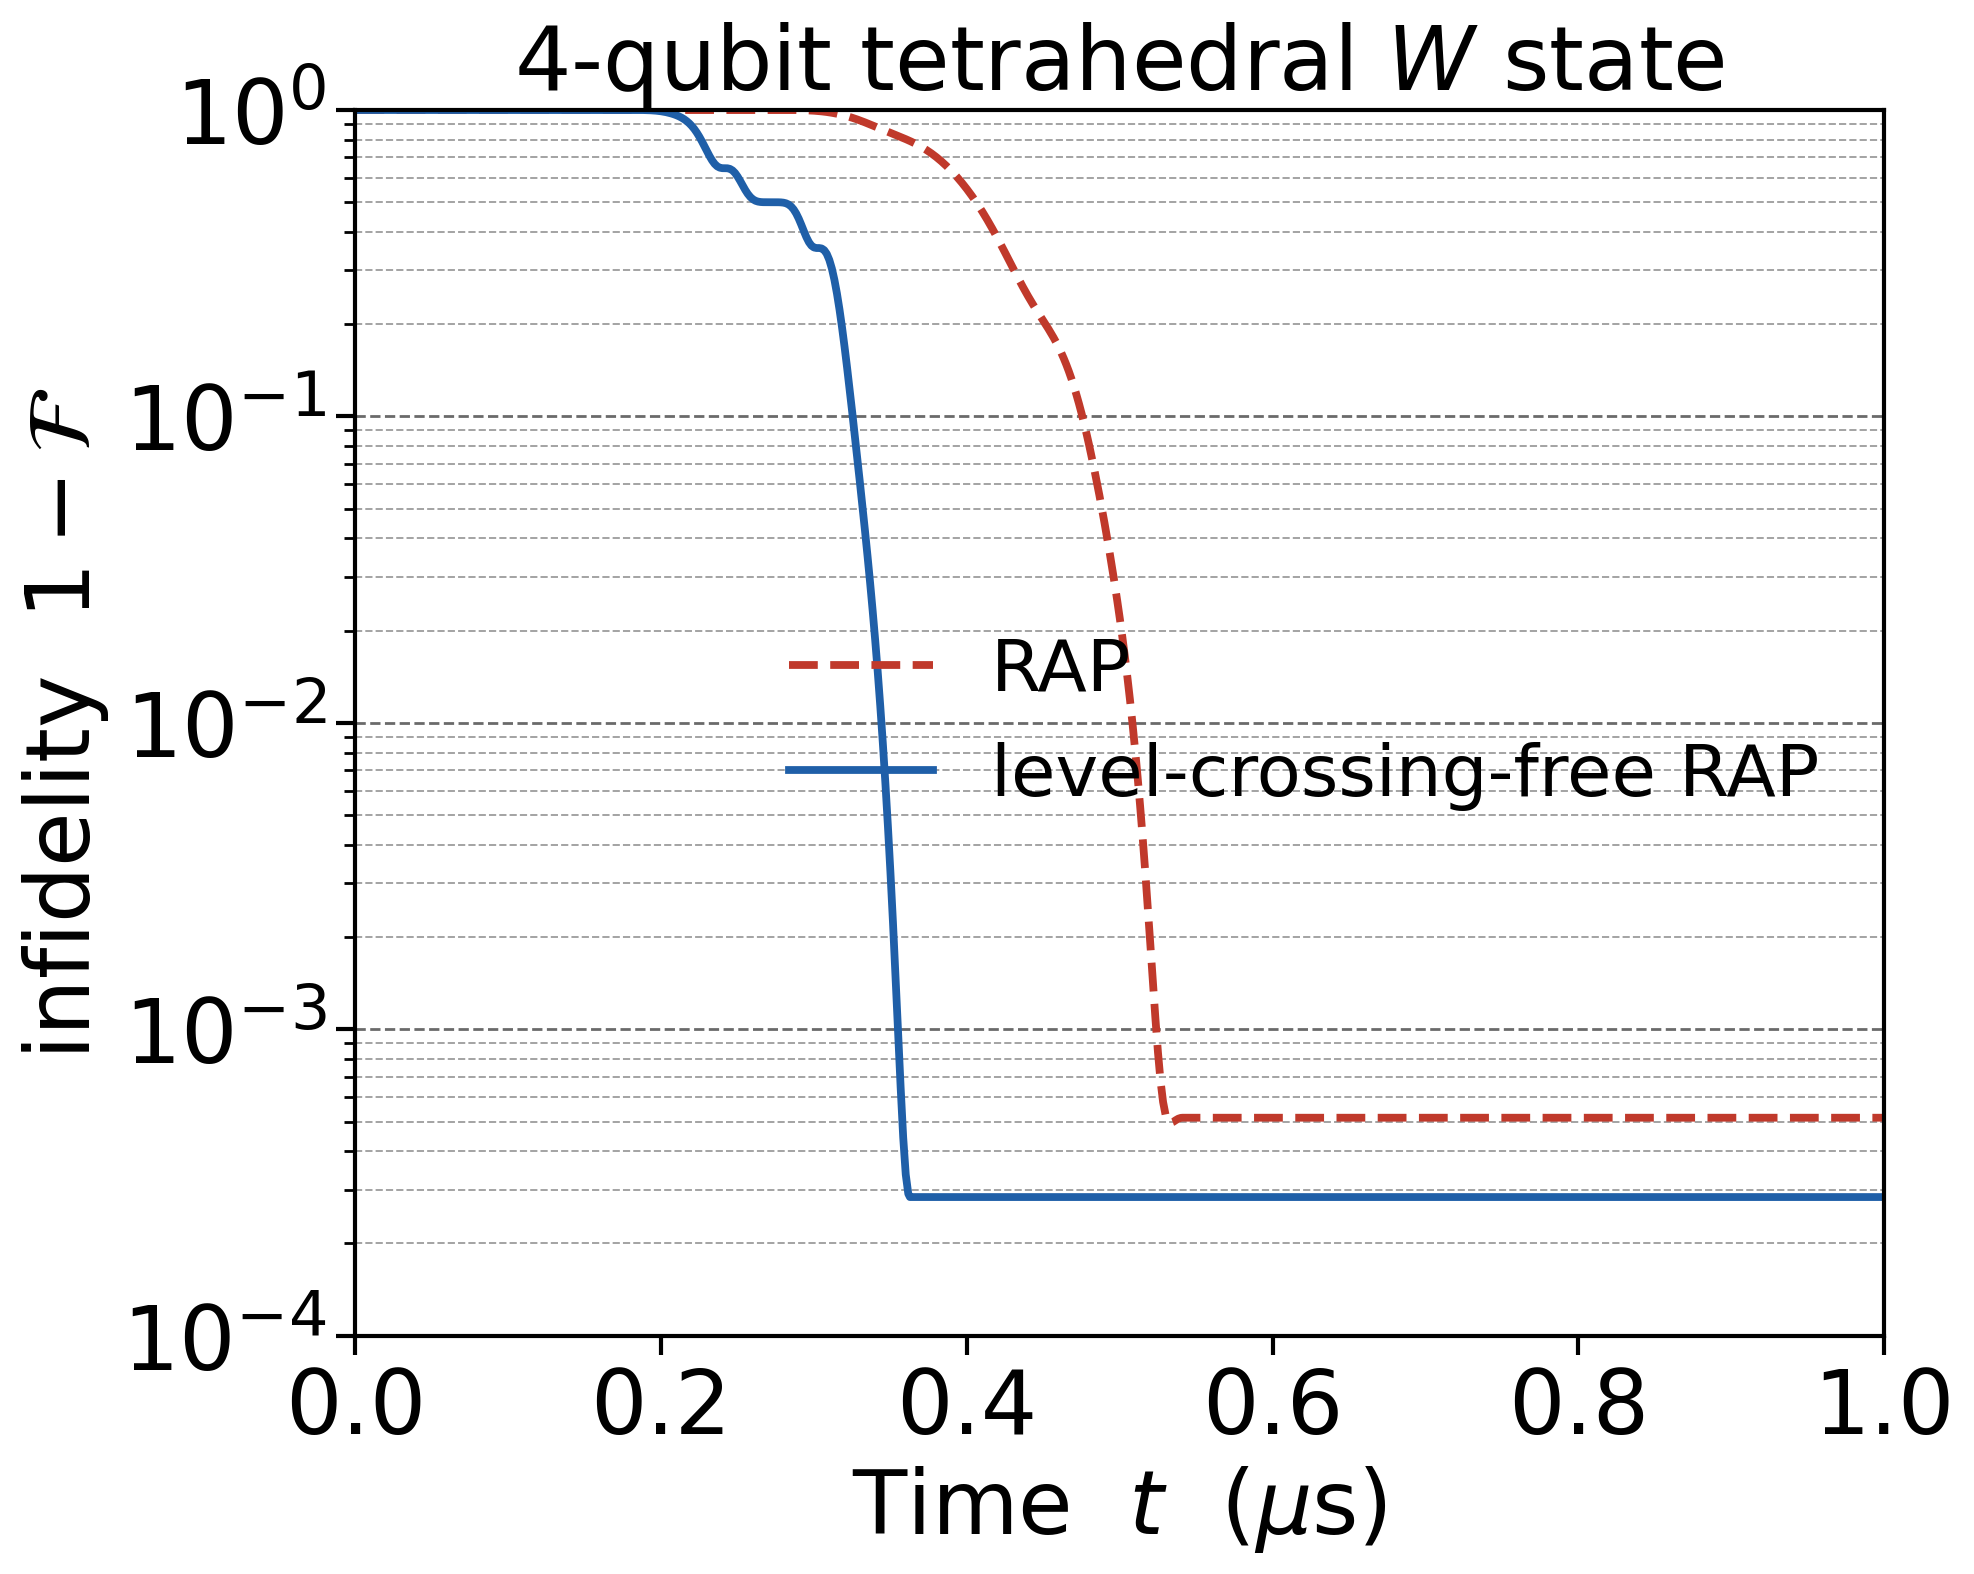

In [3]:
# -*- coding: utf-8 -*-
"""
4 比特随 t 非保真度演化：完整 Lindblad 主方程版
主方程: dr = -i[H,ρ] + Σ_k (L_k ρ L_k† - ½{L_k†L_k, ρ})
"""
# ============================================================
# Cell 1：放在最前面
# ============================================================
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import os
import sys
import numpy as np
from itertools import product as iproduct
import scipy.sparse as sp
from scipy.integrate import solve_ivp
import matplotlib
import matplotlib.pyplot as plt

SQRT2E = np.sqrt(2 * np.e)
T_END = 1.0
NPT = 601

# ==================== 基矢与算符 ====================
def build_system(n, Vmat):
    states = [''.join(p) for p in iproduct('01r', repeat=n)]
    idx = {s: i for i, s in enumerate(states)}
    dim = 3 ** n
    I3 = sp.identity(3, format='csr', dtype=complex)
    Pr = sp.csr_matrix(np.diag([0., 0., 1.]).astype(complex))
    R1 = sp.csr_matrix(np.array([[0, 0, 0], [0, 0, 0], [0, 1, 0]], dtype=complex))
    J0 = sp.csr_matrix(np.array([[0, 0, 1], [0, 0, 0], [0, 0, 0]], dtype=complex))
    J1 = sp.csr_matrix(np.array([[0, 0, 0], [0, 0, 1], [0, 0, 0]], dtype=complex))
    def embed(A, i):
        out = sp.identity(1, format='csr', dtype=complex)
        for k in range(n):
            out = sp.kron(out, A if k == i else I3, format='csr')
        return out
    Nr = sp.csr_matrix((dim, dim), dtype=complex)
    C = sp.csr_matrix((dim, dim), dtype=complex)
    jumps = []
    for i in range(n):
        Nr = Nr + embed(Pr, i)
        Ri = embed(R1, i)
        C = C + Ri + Ri.T
        jumps += [embed(J0, i), embed(J1, i), embed(Pr, i)]
    Vd = np.array([sum(Vmat[i][j] for i in range(n) for j in range(i + 1, n)
                       if s[i] == 'r' and s[j] == 'r') for s in states])
    perm = np.array([idx[s.translate(str.maketrans('01', '10'))] for s in states])
    return states, idx, dim, Nr, C, sp.diags(Vd), jumps, perm

def liouvillian_diss(jumps, rates, dim):
    """完整 Lindblad 超算符（列优先 vec）"""
    I = sp.identity(dim, format='csr', dtype=complex)
    L = sp.csr_matrix((dim * dim, dim * dim), dtype=complex)
    for Lk, g in zip(jumps, rates):
        LdL = (Lk.conjugate().T @ Lk).tocsr()
        Lc = Lk.copy(); Lc.data = Lc.data.conjugate()
        L = L + g * (sp.kron(Lc, Lk, format='csr')
                     - 0.5 * sp.kron(I, LdL, format='csr')
                     - 0.5 * sp.kron(LdL.T, I, format='csr'))
    return L

# ==================== 两套脉冲 ====================
def pulse_rap(tau_tot, om_max, del_max, fR=0.175, fD=0.5):
    tauR, tauD = fR * tau_tot, fD * tau_tot
    a = np.exp(-(tau_tot / (4 * tauR)) ** 4)
    def f(tau):
        k = 1 if tau < tau_tot / 2 else 2
        tk = (2 * k - 1) * tau_tot / 4
        Om = om_max * (np.exp(-((tau - tk) / tauR) ** 4) - a) / (1 - a)
        De = (-1) ** (k + 1) * del_max * np.sin(np.pi * (tau - tk) / tauD)
        return Om, De
    return f

def pulse_opt(tau_tot, om_max, del_max, sR, sD, pf=0.5):
    tpi = pf * tau_tot
    def f(tau):
        tm = tpi / 2 if tau < tpi else tpi + (tau_tot - tpi) / 2
        xR = (tau - tm) / sR
        xD = (tau - tm) / sD
        Om = -om_max * SQRT2E * xR * np.exp(-xR ** 2)
        De = del_max * np.e * xD ** 2 * np.exp(-xD ** 2)
        return Om, De
    return f

# ==================== 构型 ====================
def Vfull(n, V0):
    return [[V0 if i != j else 0.0 for j in range(n)] for i in range(n)]

GAMMA_CS = 1 / 540.0
GAMMA_RB = 1 / 147.0
_R2Q, _R3Q = 0.70 / 0.17, 0.73 / 0.17
W4_TARGET = [('1000', 1), ('0100', 1), ('0010', 1), ('0001', 1)]

OMEGA0      = 2 * np.pi * 100.0
TAU_TOT_4Q  = 227.91
OM_MAX_4Q   = 0.4017
DE_MAX_4Q   = 0.2558
S_R_4Q      = 23.76
S_D_4Q      = 41.51
PF_4Q       = 0.5
V0_4Q       = 5.2799

CASES = {
    'RAP-4q': dict(n=4, family='RAP', V=Vfull(4, _R3Q),
                   tau_tot=340.0 * 0.17, om_max=1.0, del_max=0.24 / 0.17,
                   gamma_r=GAMMA_CS, init='1111', target=W4_TARGET,
                   R_ref=2 * np.pi * 17.0),
    'OPT-4q': dict(n=4, family='OPT', V=Vfull(4, V0_4Q), tau_tot=TAU_TOT_4Q,
                   om_max=OM_MAX_4Q, del_max=DE_MAX_4Q,
                   sR=S_R_4Q, sD=S_D_4Q, pf=PF_4Q,
                   gamma_r=GAMMA_CS, init='1111', target=W4_TARGET,
                   R_ref=OMEGA0),
}

# ==================== 门 + 自由演化 ====================
def trajectory(cfg, R, rtol=3e-8, atol=3e-10):
    n = cfg['n']
    states, idx, dim, Nr, C, Vs, jumps, perm = build_system(n, cfg['V'])
    tau_tot = cfg['tau_tot']
    gam = cfg['gamma_r'] / R
    Ld = liouvillian_diss(jumps, [gam / 16, gam / 16, 7 * gam / 8] * n, dim)
    f = (pulse_rap(tau_tot, cfg['om_max'], cfg['del_max'])
         if cfg['family'] == 'RAP' else
         pulse_opt(tau_tot, cfg['om_max'], cfg['del_max'],
                   cfg['sR'], cfg['sD'], cfg.get('pf', 0.5)))
    def rhs_drive(tau, y):
        rho = y.reshape((dim, dim), order='F')
        Om, De = f(tau)
        H = De * Nr + 0.5 * Om * C + Vs
        return (-1j * (H @ rho - rho @ H)).reshape(-1, order='F') + Ld @ y
    def rhs_free(tau, y):
        rho = y.reshape((dim, dim), order='F')
        H = Vs
        return (-1j * (H @ rho - rho @ H)).reshape(-1, order='F') + Ld @ y
    psi0 = np.zeros(dim, complex); psi0[idx[cfg['init']]] = 1.0
    y0 = np.outer(psi0, psi0.conj()).reshape(-1, order='F')
    t_gate = tau_tot / R
    t_phys = np.linspace(0, T_END, NPT)
    tau_all = R * t_phys
    tpi = cfg.get('pf', 0.5) * tau_tot
    end = tau_tot
    tau_free_end = R * T_END
    m1 = tau_all <= tpi
    te1 = np.unique(np.append(tau_all[m1], tpi))
    s1 = solve_ivp(rhs_drive, (0, tpi), y0, method='DOP853',
                   rtol=rtol, atol=atol, t_eval=te1)
    rmid = s1.y[:, -1].reshape((dim, dim), order='F')[np.ix_(perm, perm)]
    y1 = rmid.reshape(-1, order='F')
    m2 = (tau_all > tpi) & (tau_all <= end)
    te2 = np.unique(np.append(tau_all[m2], end))
    s2 = solve_ivp(rhs_drive, (tpi, end), y1, method='DOP853',
                   rtol=rtol, atol=atol, t_eval=te2)
    m3 = tau_all > end
    te3 = np.unique(np.append(tau_all[m3], tau_free_end))
    s3 = solve_ivp(rhs_free, (end, tau_free_end), s2.y[:, -1],
                   method='DOP853', rtol=rtol, atol=atol, t_eval=te3)
    TAU = np.concatenate([s1.t, s2.t[1:], s3.t[1:]])
    Y = np.hstack([s1.y, s2.y[:, 1:], s3.y[:, 1:]])
    tv = np.zeros(dim, complex)
    for s_, amp in cfg['target']:
        tv[idx[s_]] += amp
    tv /= np.linalg.norm(tv)
    infid = np.array([1.0 - float(np.real(tv.conj()
                        @ Y[:, m].reshape((dim, dim), order='F') @ tv))
                      for m in range(Y.shape[1])])
    Pr = np.zeros(dim)
    Pr[[idx[s_] for s_ in states if 'r' in s_]] = 1.0
    rho_end = s2.y[:, -1].reshape((dim, dim), order='F')
    r_pop = float(np.real(np.trace(rho_end @ np.diag(Pr))))
    return TAU / R, infid, t_gate, r_pop

# ==================== 主程序 ====================
if __name__ == '__main__':
    res = {}
    for key in ['RAP-4q', 'OPT-4q']:
        cfg = CASES[key]
        R = cfg['R_ref']
        t, inf, tg, rp = trajectory(cfg, R)
        res[key] = (t, inf, tg)
        i_gate = int(np.argmin(np.abs(t - tg)))
        i_end = int(np.argmin(np.abs(t - T_END)))


    LC = {'RAP': '#c0392b', 'OPT': '#1f5fa8'}
    LS = {'RAP': '--', 'OPT': '-'}
    LABEL = {'RAP': 'RAP', 'OPT': 'level-crossing-free RAP'}
    FS_LAB = FS_TCK = FS_TIT = 32
    fig, ax = plt.subplots(figsize=(10.0, 8.0))
    for key in ['RAP-4q', 'OPT-4q']:
        t, inf, tg = res[key]
        fam = key[:3]
        ax.plot(t, inf, LS[fam], color=LC[fam], lw=2.8, label=LABEL[fam])
    ax.set_yscale('log')
    YTICKS = [1e0, 1e-1, 1e-2, 1e-3, 1e-4]
    ax.set_ylim(YTICKS[-1], YTICKS[0])
    ax.set_xlim(0, T_END)
    ax.set_xlabel(r'Time  $t$  ($\mu$s)', fontsize=FS_LAB)
    ax.set_ylabel(r'infidelity  $1-\mathcal{F}$', fontsize=FS_LAB)
    ax.set_title(r'4-qubit tetrahedral $W$ state', fontsize=FS_TIT)
    ax.tick_params(axis='both', which='major', labelsize=FS_TCK, width=1.5, length=7)
    ax.tick_params(axis='both', which='minor', width=1.0, length=4)
    ax.set_yticks(YTICKS)
    for yv in YTICKS:
        ax.axhline(yv, color='0.1', lw=1.0, ls='--', alpha=.65, zorder=0)
    SUB = np.array([2, 3, 4, 5, 6, 7, 8, 9], dtype=float)
    for yv in YTICKS[:-1]:
        for m in SUB:
            ax.axhline(yv * m / 10.0, color='0.2', lw=0.7, ls='--',
                       alpha=.45, zorder=0)
    leg = ax.legend(fontsize=FS_TCK - 6, loc='best', frameon=False)
    for sp_ in ax.spines.values():
        sp_.set_linewidth(1.5)
    plt.tight_layout()

    try:
        output_path = os.path.join(os.path.dirname(os.path.abspath(__file__)),
                                   'tetrahedron_W4_infid_vs_time_Lindblad.png')
    except NameError:
        output_path = 'tetrahedron_W4_infid_vs_time_Lindblad.png'

    plt.savefig(output_path, dpi=170)
 

  行 21/21 完成 (133s)

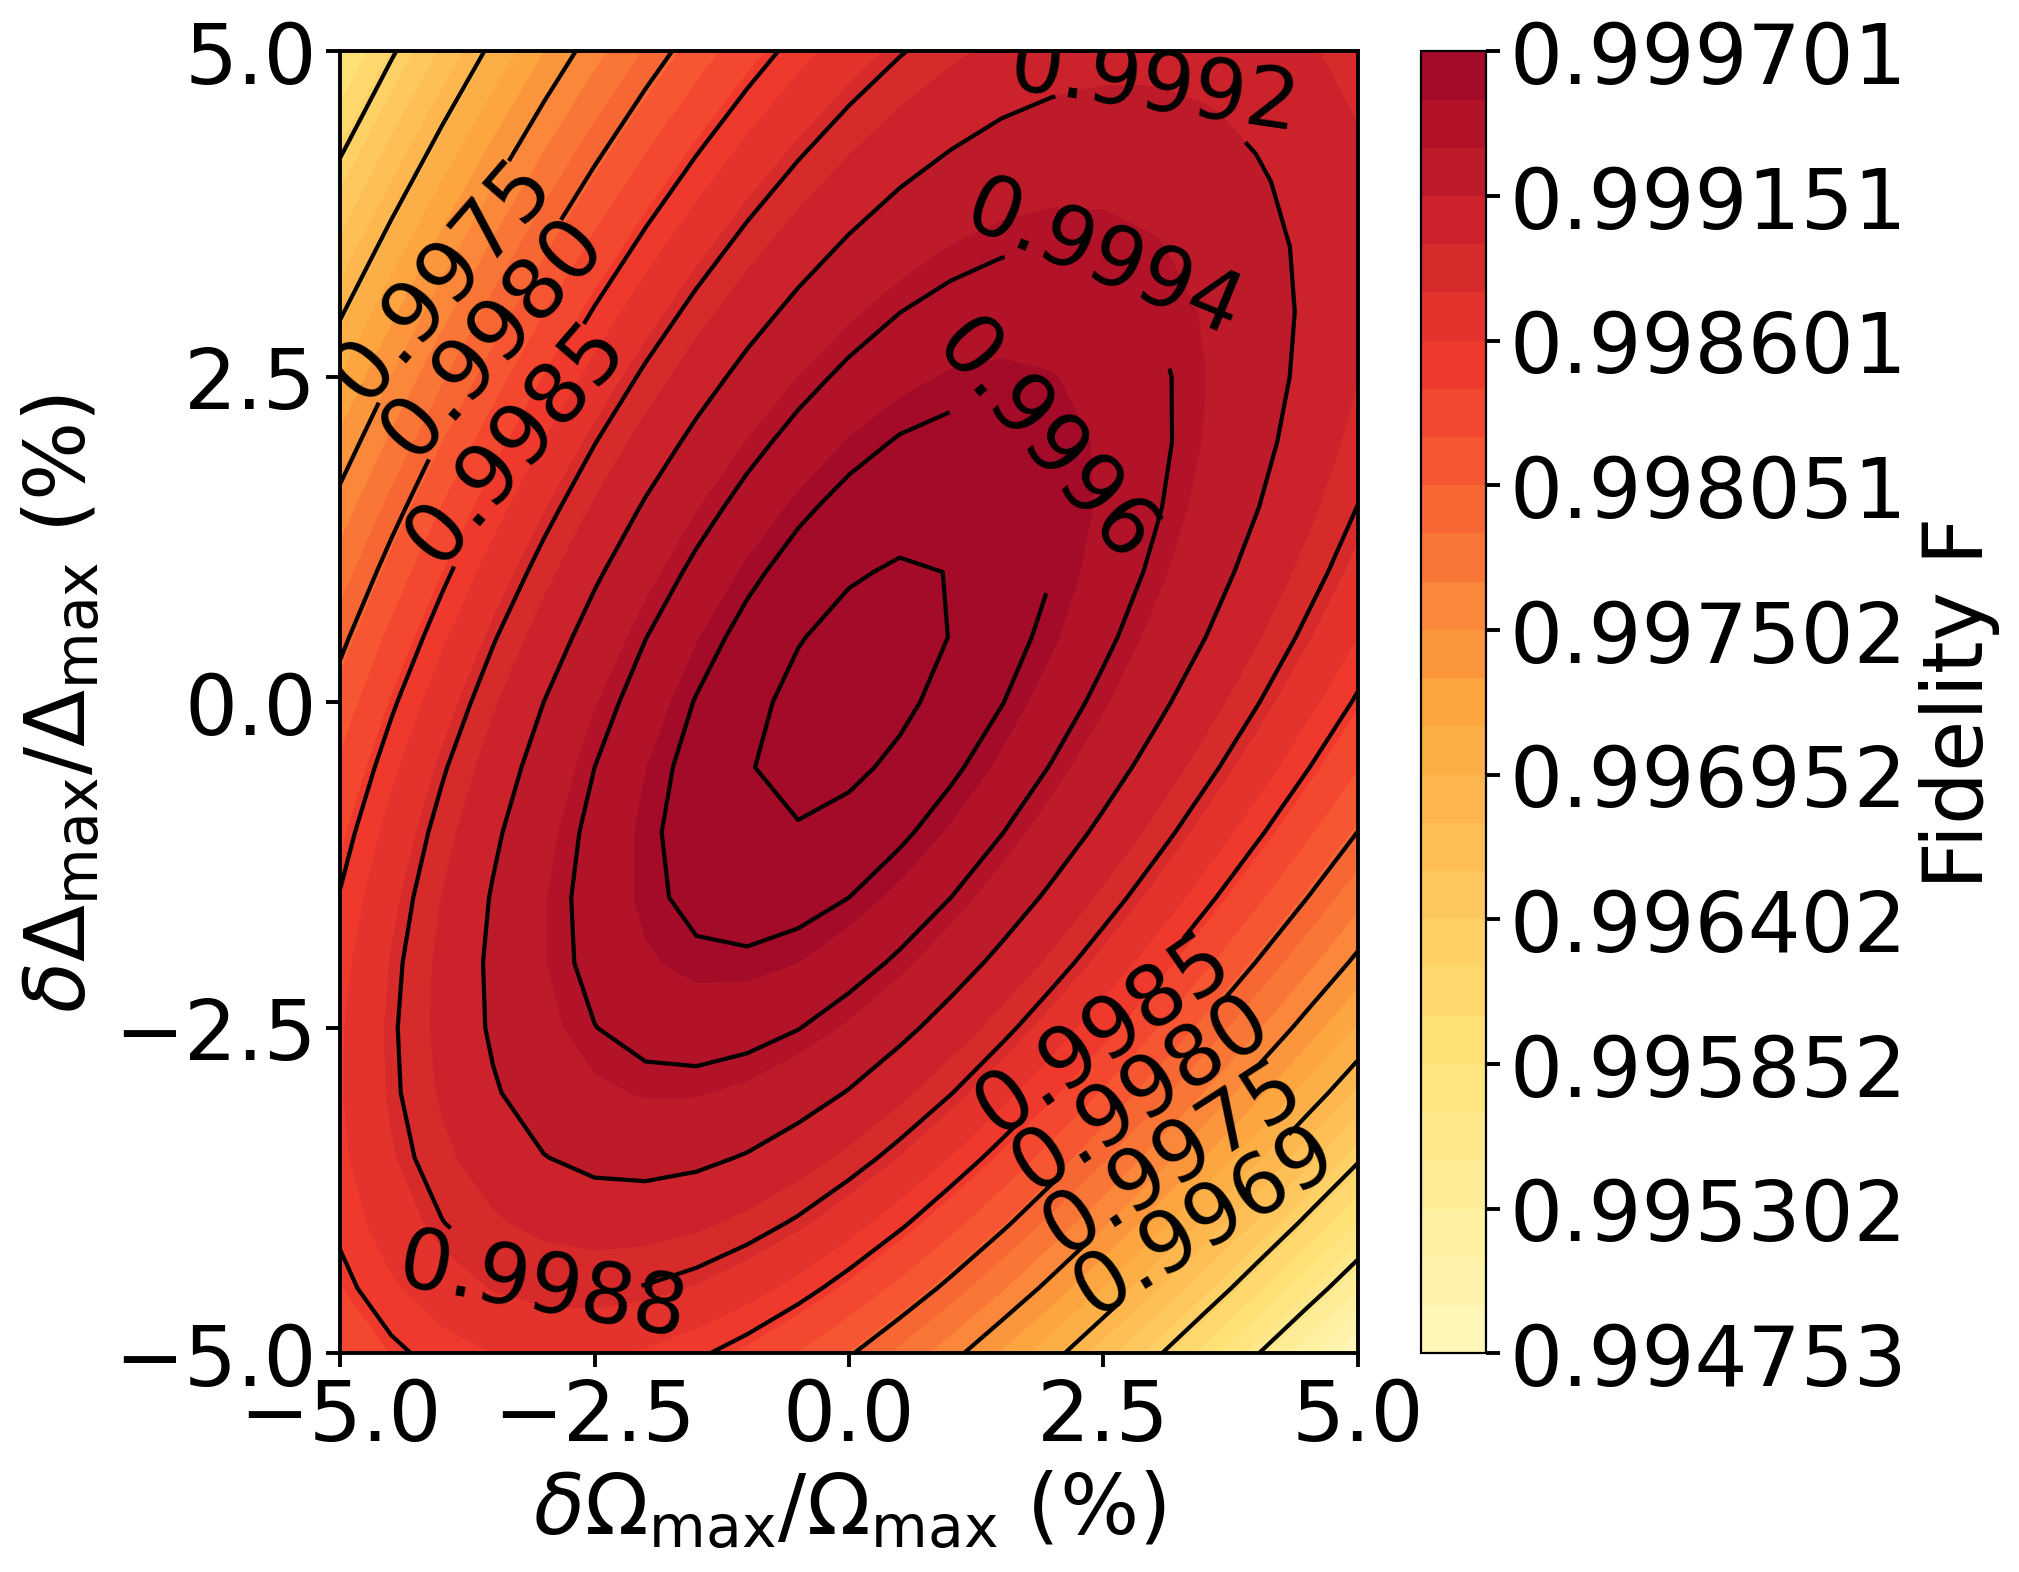

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from itertools import product

# ==================== 物理参数 (2π×MHz 与 µs) ====================
Omega10 = 2*np.pi*100.0        # Ω10 = 2π×100 MHz ≈ 628.32 rad/µs
gamma_r = 1.0/540.0            # 里德堡态总耗散率 (Cs |107P3/2>), 540 µs 寿命

# ==================== 脉冲参数：替换为 "2比特 (2).txt" 的优化脉冲 ====================
tau_tot = 290.9825033647375
OM1max  = 0.2969771
DE1max  = 0.1750508
sR      = 32.55720053835801
sD      = 60.67294751009421
PF      = 0.500
V0      = 3.9167245

# 无量纲耗散率
Gamma = gamma_r/Omega10
# 各通道耗散率
Gamma_spont = Gamma / 16.0     # 每通道自发辐射率 (r→0, r→1)
Gamma_deph  = 7.0 * Gamma / 8.0  # 退相位率

# ==================== 9 维 Hilbert 空间 ====================
st = [''.join(p) for p in product('01r', repeat=2)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)

Cc = np.zeros((d, d))                        # 耦合 Σ_a (|r><1|+h.c.)/2
for s, i in idx.items():
    for a in range(2):
        if s[a] == '1':
            Cc[idx[s[:a]+'r'+s[a+1:]], i] = 0.5
        elif s[a] == 'r':
            Cc[idx[s[:a]+'1'+s[a+1:]], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Dr = np.diag(n_r)                            # 失谐项 (|rr⟩ 计 2Δ)
Err = np.zeros((d, d)); Err[idx['rr'], idx['rr']] = 1.0
g_perm = np.array([idx[s.replace('0', '_').replace('1', '0').replace('_', '1')]
                   for s in st])             # πg 置换 (0↔1)

psi0 = np.zeros(d, complex); psi0[idx['11']] = 1.0
psiT = np.zeros(d, complex)
psiT[idx['01']] = 1/np.sqrt(2); psiT[idx['10']] = 1/np.sqrt(2)


# ==================== Lindblad 跳跃算符（完整形式） ====================
# 自发辐射 r → 0, r → 1（每个原子）
L_ops = []
for a in range(2):
    for ch in ('0', '1'):
        L = np.zeros((d, d), dtype=complex)
        for s, i in idx.items():
            if s[a] == 'r':
                j = idx[s[:a]+ch+s[a+1:]]
                L[j, i] = np.sqrt(Gamma_spont)
        L_ops.append(L)
# 退相位（每个原子）
for a in range(2):
    diag = np.array([1.0 if s[a] == 'r' else 0.0 for s in st], dtype=float)
    L_ops.append(np.sqrt(Gamma_deph) * np.diag(diag))

# 预计算 L†L
LdL_list = [L.conj().T @ L for L in L_ops]


def lindblad_rhs(rho, H):
    """完整 Lindblad 主方程:
       dr = -i[H,ρ] + Σ_k (L_k ρ L_k† - ½{L_k†L_k, ρ})"""
    dr = -1j * (H @ rho - rho @ H)
    for L, LdL in zip(L_ops, LdL_list):
        dr = dr + L @ rho @ L.conj().T - 0.5 * (LdL @ rho + rho @ LdL)
    return dr


# ==================== 脉冲 (高斯导数型, 无量纲) ====================
def pulse(tau):
    tau = np.asarray(tau, float)
    tau_pi = PF*tau_tot
    tm = np.where(tau <= tau_pi, tau_pi/2, tau_pi + (tau_tot - tau_pi)/2)
    xR = (tau - tm)/sR
    xD = (tau - tm)/sD
    Om = -np.sqrt(2*np.e)*xR*np.exp(-xR**2)
    De = np.e*xD**2*np.exp(-xD**2)
    return Om, De


def fidelity(dO=0.0, dD=0.0, dt=0.05, diss=True):
    """dO/dD: Ω1max、Δ1max 的相对误差 (%)。支持批量 (广播) 计算。"""
    dO = np.atleast_1d(np.asarray(dO, float))
    dD = np.atleast_1d(np.asarray(dD, float))
    OmM, DeM = OM1max*(1+dO/100), DE1max*(1+dD/100)   # 有效峰值
    DrG, CcG, ErrG = Dr[None], Cc[None], V0*Err[None]

    def deriv(rho, Om, De):
        # 注意: Om, De 已是 pulse(t)*峰值 的无量纲量, 直接乘峰值即可
        H = De[:, None, None]*DrG + Om[:, None, None]*CcG + ErrG
        dr = -1j*(H@rho - rho@H)
        if diss:
            for L, LdL in zip(L_ops, LdL_list):
                Lc = L.conj().T
                dr += (L[None] @ rho @ Lc[None]
                       - 0.5*(LdL[None] @ rho + rho @ LdL[None]))
        return dr

    N = int(round(tau_tot/dt))
    n_pi = int(round(PF*N))
    rho = np.zeros((dO.size, d, d), complex)
    rho[:, idx['11'], idx['11']] = 1.0
    for n in range(N):
        t0 = n*dt
        Om0, De0 = pulse(t0)
        Omh, Deh = pulse(t0+dt/2)
        Om1, De1 = pulse(t0+dt)
        # 传无量纲的 Ω(t),Δ(t) (已是 pulse×峰值)
        k1 = deriv(rho, Om0*OmM, De0*DeM)
        k2 = deriv(rho + 0.5*dt*k1, Omh*OmM, Deh*DeM)
        k3 = deriv(rho + 0.5*dt*k2, Omh*OmM, Deh*DeM)
        k4 = deriv(rho + dt*k3, Om1*OmM, De1*DeM)
        rho = rho + dt*(k1 + 2*k2 + 2*k3 + k4)/6
        if n == n_pi - 1:                    # 中点施加 πg (时间忽略不计)
            rho = rho[:, g_perm[:, None], g_perm[None, :]]
    return np.real(np.einsum('i,gij,j->g', psiT.conj(), rho, psiT))


# ==================== ±5% 鲁棒性扫描 (21×21) ====================
if __name__ == '__main__':
    import time
    t0 = time.time()
    F0 = fidelity()[0]

    offsets = np.linspace(-5, 5, 21)
    grid = np.zeros((len(offsets), len(offsets)))
    for i, dD in enumerate(offsets):         # 行: δΔ0 误差
        grid[i, :] = fidelity(dO=offsets, dD=dD)   # 列: δΩmax 误差
        print(f"  行 {i+1}/21 完成 ({time.time()-t0:.0f}s)", end='\r')
    np.save('grid_2bit_pulse.npy', grid)

    # ==================== 画鲁棒性等高线图 ====================
    cmap_ref = LinearSegmentedColormap.from_list('ref_yor', [
        (1.000, 0.976, 0.737),   # 淡黄（低值）
        (1.000, 0.878, 0.451),   # 黄
        (0.992, 0.651, 0.247),   # 橙
        (0.953, 0.231, 0.176),   # 红橙
        (0.624, 0.031, 0.157),   # 深红（高值）
    ])
    FS_LAB = 30
    FS_TCK = 30

    f_min, f_max = float(np.nanmin(grid)), float(np.nanmax(grid))
    if np.isclose(f_min, f_max):
        pad = max(abs(f_min)*1e-6, 1e-9)
        f_min, f_max = f_min - pad, f_max + pad

    fill_levels = np.linspace(f_min, f_max, 28)

    level_pos = np.linspace(0.0, 1.0, 13)[1:-1]
    line_levels = f_min + (f_max - f_min)*(1.0 - (1.0 - level_pos)**2)

    fig, ax = plt.subplots(figsize=(10, 8))
    cf = ax.contourf(offsets, offsets, grid,
                     levels=fill_levels, cmap=cmap_ref)
    cs = ax.contour(offsets, offsets, grid,
                    levels=line_levels,
                    colors='black', linewidths=1.5)
    ax.clabel(cs, fmt='%.4f', fontsize=30, colors='black', inline_spacing=3)
    cbar = plt.colorbar(cf, ax=ax)
    cbar.set_label('Fidelity F', fontsize=FS_LAB)
    cbar.ax.tick_params(labelsize=FS_TCK, width=1.4, length=5)
    ax.set_xlabel(r'$\delta\Omega_{\max}/\Omega_{\max}$ (%)', fontsize=FS_LAB)
    ax.set_ylabel(r'$\delta\Delta_{\max}/\Delta_{\max}$ (%)', fontsize=FS_LAB)
    ax.tick_params(axis='both', labelsize=FS_TCK, width=1.4, length=5)
    # ===== 新增：坐标轴刻度设为 -5, -2.5, 0, 2.5, 5 =====
    ax.set_xticks([-5, -2.5, 0, 2.5, 5])
    ax.set_yticks([-5, -2.5, 0, 2.5, 5])
    for sp in ax.spines.values():
        sp.set_linewidth(1.4)
    plt.tight_layout()
    plt.savefig('fig2e_2bit_pulse.png', dpi=200)
    plt.show()


Ω0/2π = 100.0 MHz,  最优 Ωmax = 35.67 MHz, 最优 Δmax = 22.18 MHz, τ_tot = 254.65 (t_gate = 0.4053 µs)
Ω 坐标 (MHz): [32 34 36 38 40]
Δ 坐标 (MHz): [20 21 22 23 24]
计算中...
Ω=   32 MHz 行完成: F = [0.995026 0.994684 0.99376  0.993008 0.992754]
Ω=   34 MHz 行完成: F = [0.996964 0.998371 0.998531 0.9982   0.997764]
Ω=   36 MHz 行完成: F = [0.995865 0.998771 0.999661 0.999383 0.998462]
Ω=   38 MHz 行完成: F = [0.992748 0.996824 0.998153 0.997744 0.996319]
Ω=   40 MHz 行完成: F = [0.989263 0.994003 0.995453 0.994809 0.992987]

中心点含耗散保真度 F = 0.999701
网格最低值 F_min = 0.989263
网格最高值 F_max = 0.999661


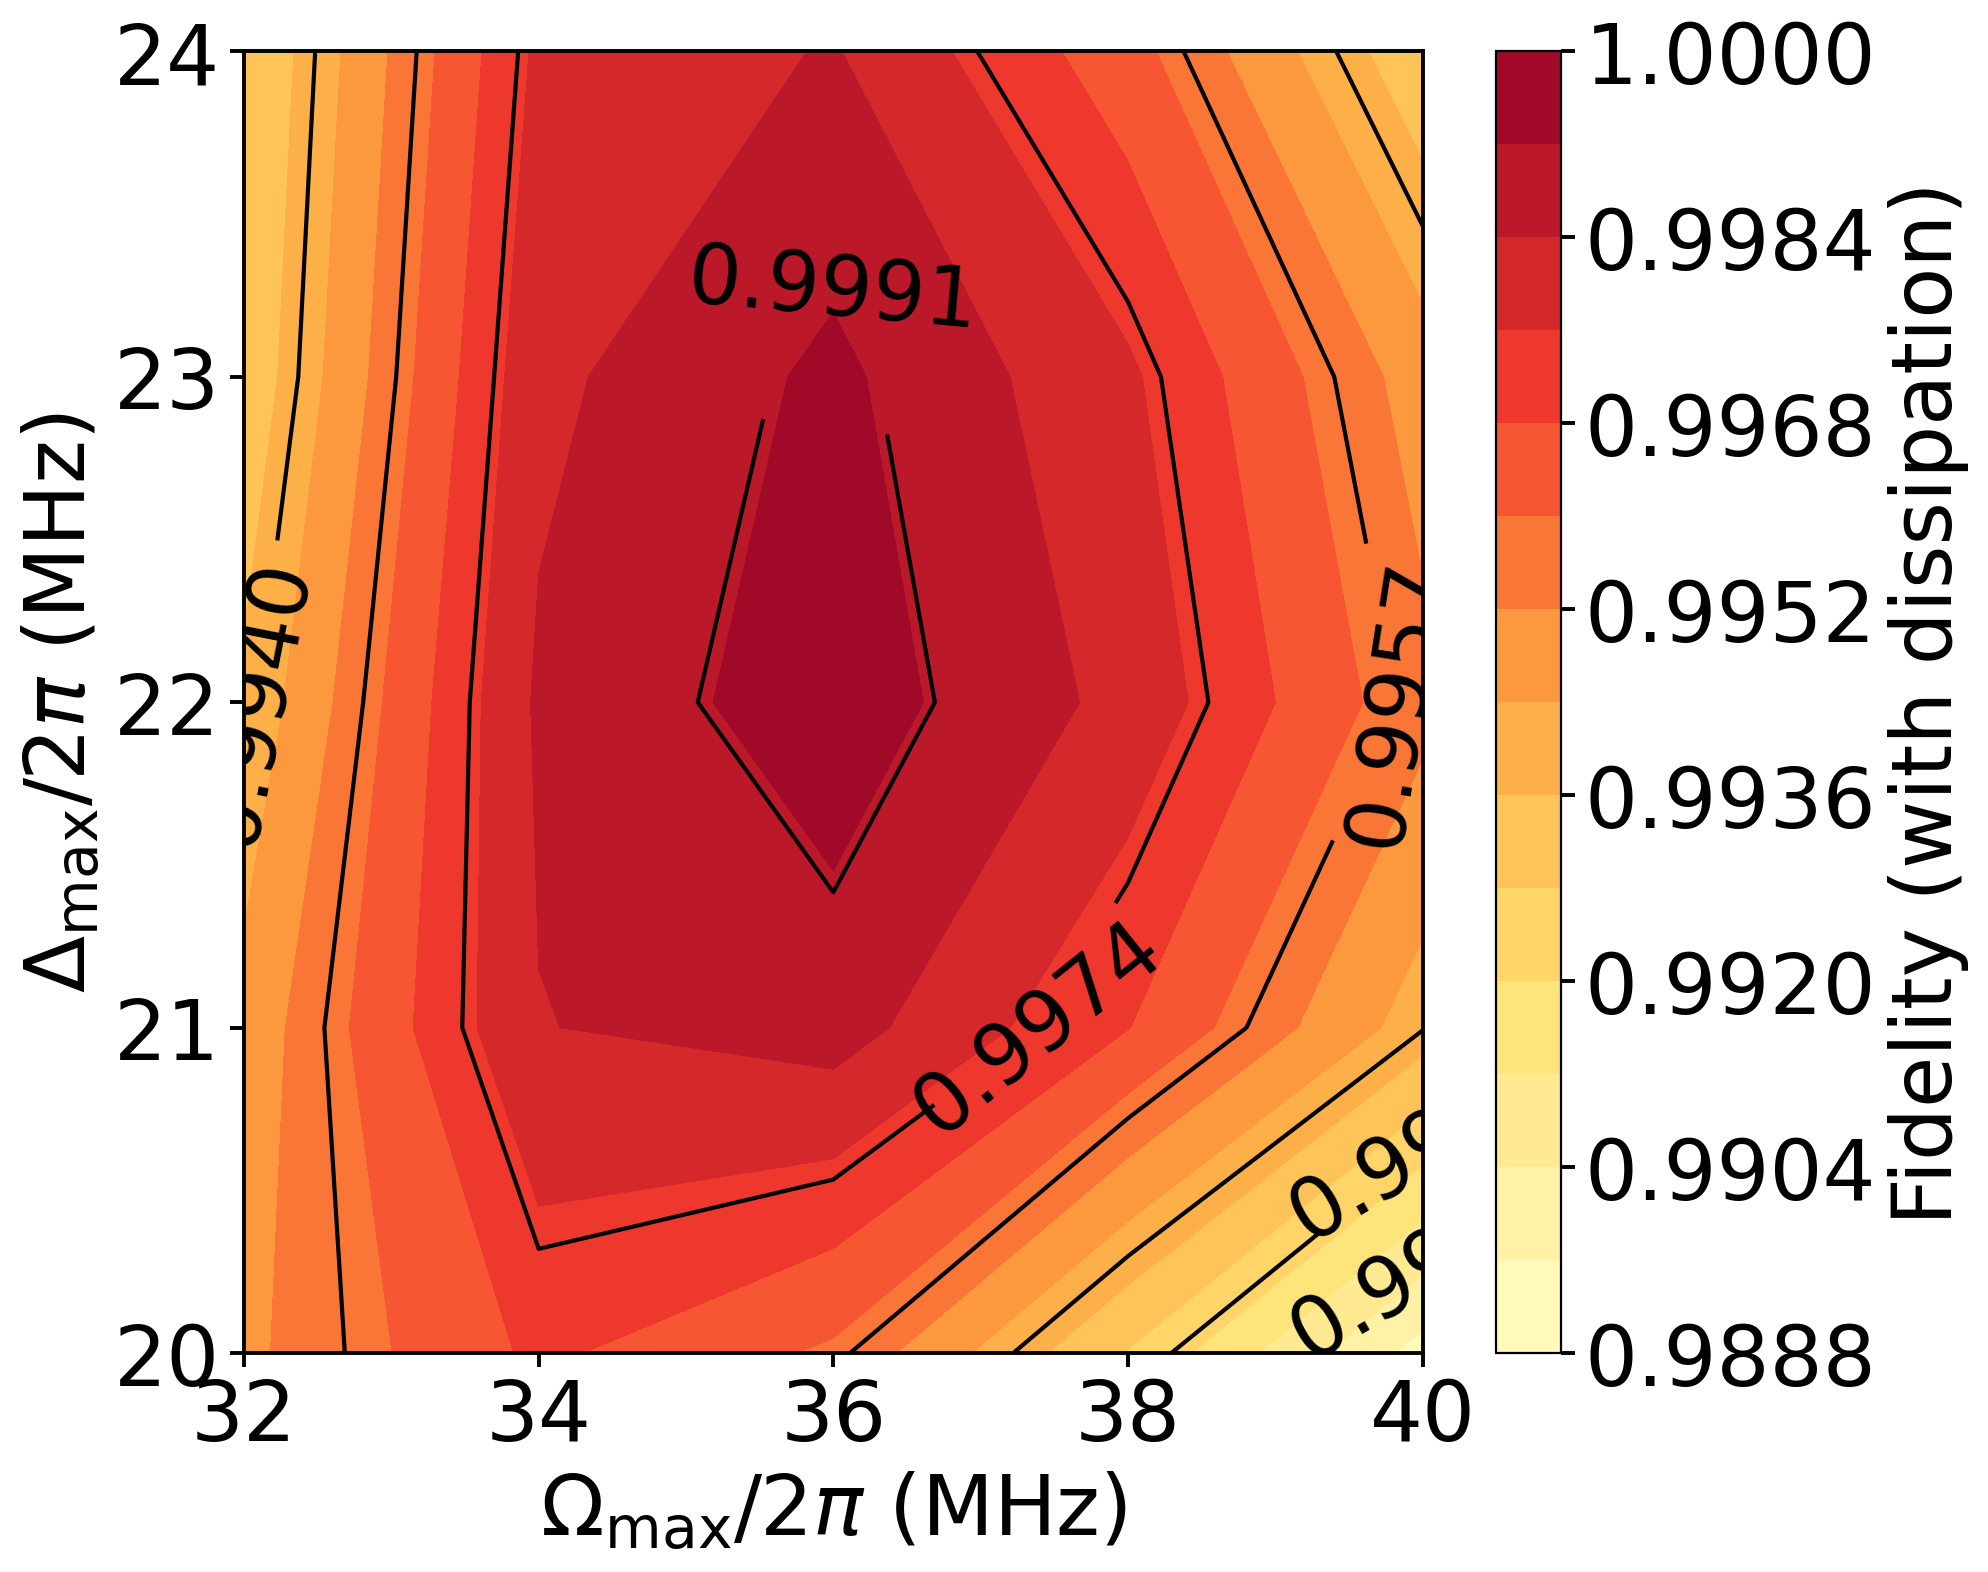


最优参数: Ωmax = 35.67 MHz, Δmax = 22.18 MHz, F = 0.999701


In [5]:
# -*- coding: utf-8 -*-
"""
三比特 W 态鲁棒性：完整 Lindblad 主方程版
主方程: dr = -i[H,ρ] + Σ_k (L_k ρ L_k† - ½{L_k†L_k, ρ})
"""
import numpy as np                      # 数值计算库
from itertools import product           # 生成基矢
import matplotlib.pyplot as plt         # 绘图
from matplotlib.colors import LinearSegmentedColormap, Normalize
import matplotlib.ticker as mticker

# ==================== 无量纲单位制 ====================
Omega10 = 2*np.pi*100.0                 # Ω0 = 2π×100 MHz（rad/µs）

# ---- 无量纲脉冲参数 ----
TAU_TOT = 254.64804469273741    # 无量纲总时长 → t_tot = TAU_TOT/Ω10 µs
OM1max  = 0.356747             # Ωmax (Ω10 单位)
DE1max  = 0.22176485870975582  # Δ0 峰值 (Ω10 单位)
sR      = 27.050279329608937   # Ω 包络宽度 (无量纲)
sD      = 47.3815270018622     # Δ 包络宽度 (无量纲)
pf      = 0.501                 # πg 位置 (t_π = pf·tau_tot)
V0      = 4.319068724444445    # 相互作用 (Ω10 单位) 

# ---- 无量纲耗散率 ----
gamma_r     = 1.0/540.0
Gamma       = gamma_r/Omega10
Gamma_spont = Gamma/16
Gamma_deph  = 7*Gamma/8
N_step      = 1200

# ==================== 全 Hilbert 空间（3 原子，27 维） ====================
N = 3
st = [''.join(p) for p in product('01r', repeat=N)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)

C = np.zeros((d, d), dtype=complex)
for s, i in idx.items():
    for a in range(N):
        if s[a] == '1':   s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r': s2 = s[:a]+'1'+s[a+1:]
        else: continue
        C[idx[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
E_i = np.array([V0*(s.count('r')*(s.count('r')-1)//2) for s in st], float)
g_perm = np.array([idx[s.replace('0','_').replace('1','0').replace('_','1')]
                   for s in st])

# 初态 |111> 与目标 W3 态
psi0 = np.zeros(d, complex); psi0[idx['111']] = 1.0
psiT = np.zeros(d, complex)
for a in range(N):
    s = ['0']*N; s[a] = '1'
    psiT[idx[''.join(s)]] = 1/np.sqrt(N)

# ==================== Lindblad 跳跃算符（完整形式） ====================
L_ops = []
for a in range(N):
    for ch in ('0', '1'):
        L = np.zeros((d, d), dtype=complex)
        for s, i in idx.items():
            if s[a] == 'r':
                j = idx[s[:a]+ch+s[a+1:]]
                L[j, i] = np.sqrt(Gamma_spont)
        L_ops.append(L)
for a in range(N):
    diag = np.array([1.0 if s[a] == 'r' else 0.0 for s in st], dtype=float)
    L_ops.append(np.sqrt(Gamma_deph) * np.diag(diag))
LdL_list = [L.conj().T @ L for L in L_ops]

# ==================== 含耗散保真度（Strang 分裂 + 完整 Lindblad） ====================
tau  = (np.arange(N_step)+0.5)*TAU_TOT/N_step
tau_pi = pf*TAU_TOT
tm = np.where(tau < tau_pi, tau_pi/2, tau_pi + (TAU_TOT - tau_pi)/2)
xR = (tau-tm)/sR; xD = (tau-tm)/sD
base_Om = -OM1max*np.sqrt(2*np.e)*xR*np.exp(-xR**2)
base_De = DE1max*np.e*xD**2*np.exp(-xD**2)
dtau = TAU_TOT/N_step
n_pi = int(round(pf*N_step))

def fidelity(Om_scale=1.0, D0_scale=1.0):
    H = (base_Om*Om_scale)[:, None, None]*C[None]
    H[:, np.arange(d), np.arange(d)] += (base_De*D0_scale)[:, None]*n_r[None] + E_i[None]
    w, v = np.linalg.eigh(H)
    Uh = v*np.exp(-1j*w*dtau/2)[:, None, :] @ np.swapaxes(v.conj(), 1, 2)
    rho = np.outer(psi0, psi0.conj())
    for n in range(N_step):
        rho = Uh[n] @ rho @ Uh[n].conj().T
        # 完整 Lindblad 耗散（半步）
        jump = np.zeros_like(rho)
        for L, LdL in zip(L_ops, LdL_list):
            Lc = L.conj().T
            jump += L @ rho @ Lc - 0.5*(LdL @ rho + rho @ LdL)
        rho = rho + dtau*jump
        rho = Uh[n] @ rho @ Uh[n].conj().T
        if n == n_pi - 1:
            rho = rho[np.ix_(g_perm, g_perm)]
    return np.real(psiT.conj() @ rho @ psiT)

# ==================== 鲁棒性扫描（自适应坐标） ====================
SPAN_PCT = 10.0
NPT_AX   = 5

def adaptive_int_axis(center_MHz, span_pct=SPAN_PCT, npt=NPT_AX):
    c = int(round(center_MHz))
    half = center_MHz*span_pct/100.0
    step = max(1, int(round(2*half/(npt-1))))
    m = npt//2
    return np.array([c + k*step for k in range(-m, npt-m)], dtype=float)

OM_max_MHz = OM1max*Omega10/(2*np.pi)
DE_max_MHz = DE1max*Omega10/(2*np.pi)
Omega_values_MHz = adaptive_int_axis(OM_max_MHz)
Delta_values_MHz = adaptive_int_axis(DE_max_MHz)
Omega_scales = Omega_values_MHz/OM_max_MHz
Delta_scales = Delta_values_MHz/DE_max_MHz

grid = np.zeros((len(Omega_scales), len(Delta_scales)))

print(f"Ω0/2π = {Omega10/(2*np.pi):.1f} MHz,  "
      f"最优 Ωmax = {OM_max_MHz:.2f} MHz, 最优 Δmax = {DE_max_MHz:.2f} MHz, "
      f"τ_tot = {TAU_TOT:.2f} (t_gate = {TAU_TOT/Omega10:.4f} µs)")
print("Ω 坐标 (MHz):", Omega_values_MHz.astype(int))
print("Δ 坐标 (MHz):", Delta_values_MHz.astype(int))
print("计算中...")
for i, Om_scale in enumerate(Omega_scales):
    for j, D_scale in enumerate(Delta_scales):
        grid[i, j] = fidelity(Om_scale, D_scale)
    print(f"Ω={Omega_values_MHz[i]:5.0f} MHz 行完成: "
          f"F = {np.round(grid[i], 6)}")

F0 = fidelity(1.0, 1.0)
print(f"\n中心点含耗散保真度 F = {F0:.6f}")
print(f"网格最低值 F_min = {grid.min():.6f}")
print(f"网格最高值 F_max = {grid.max():.6f}")

# ==================== 画鲁棒性等高线图（横轴 Ω、纵轴 Δ） ====================
cmap_ref = LinearSegmentedColormap.from_list('ref_yor', [
    (1.000, 0.976, 0.737),
    (1.000, 0.878, 0.451),
    (0.992, 0.651, 0.247),
    (0.953, 0.231, 0.176),
    (0.624, 0.031, 0.157),
])

vmin, vmax = float(grid.min()), float(grid.max())
if vmax - vmin < 1e-9:
    vmax = vmin + 1e-9
fill_levels = mticker.MaxNLocator(nbins=15).tick_values(vmin, vmax)

N_LINE = 6
line_levels = vmin + (vmax - vmin) * np.linspace(0.12, 0.95, N_LINE)
line_levels = np.unique(line_levels)
line_levels = line_levels[(line_levels > vmin) & (line_levels < vmax)]

FS_LAB, FS_TCK = 30, 30         # 与 2比特ΔΩ 一致
FS_CLABEL = 30                   # 与 2比特ΔΩ 一致

def clabel_once_per_level(ax, cs, fmt="%.4f", fontsize=FS_CLABEL, colors="black",
                          inline=True):
    levels_ok, pos = [], []
    for lev, segs in zip(cs.levels, cs.allsegs):
        if not len(segs):
            continue
        seg = max(segs, key=len)
        k = len(seg) // 2
        levels_ok.append(float(lev))
        pos.append((float(seg[k, 0]), float(seg[k, 1])))
    if levels_ok:
        ax.clabel(cs, levels=levels_ok, manual=pos, fmt=fmt,
                  fontsize=fontsize, colors=colors, inline=inline)
    return len(levels_ok)

fig, ax = plt.subplots(figsize=(10.0, 8.0))      # 与 2比特ΔΩ 一致


cf = ax.contourf(Omega_values_MHz, Delta_values_MHz, grid.T,
                 levels=fill_levels, cmap=cmap_ref,
                 norm=Normalize(vmin, vmax), extend='neither')

cs = ax.contour(Omega_values_MHz, Delta_values_MHz, grid.T,
                levels=line_levels, colors='black', linewidths=1.5)
clabel_once_per_level(ax, cs, fmt='%.4f', fontsize=FS_CLABEL,
                              colors='black')

cbar = plt.colorbar(cf, ax=ax)
cbar.set_label('Fidelity (with dissipation)', fontsize=FS_LAB)
cbar.ax.tick_params(labelsize=FS_TCK, width=1.4, length=5)

ax.set_xlabel(r'$\Omega_{\max}/2\pi$ (MHz)', fontsize=FS_LAB)
ax.set_ylabel(r'$\Delta_{\max}/2\pi$ (MHz)', fontsize=FS_LAB)
ax.tick_params(axis='both', labelsize=FS_TCK, width=1.4, length=5)

ax.set_xlim(Omega_values_MHz[0], Omega_values_MHz[-1])
ax.set_ylim(Delta_values_MHz[0], Delta_values_MHz[-1])
ax.set_xticks(Omega_values_MHz)
ax.set_yticks(Delta_values_MHz)
ax.set_xticklabels([f'{int(round(v)):d}' for v in Omega_values_MHz], fontsize=FS_TCK)
ax.set_yticklabels([f'{int(round(v)):d}' for v in Delta_values_MHz], fontsize=FS_TCK)

for sp in ax.spines.values():
    sp.set_linewidth(1.4)

plt.tight_layout()
plt.savefig('fig_3qubit_Omega_Delta.png', dpi=200)
plt.show()

print(f"\n最优参数: Ωmax = {OM_max_MHz:.2f} MHz, Δmax = {DE_max_MHz:.2f} MHz, F = {F0:.6f}")

=== Validation ===
F_diss = 0.99971651
Target F>=0.998: OK

Ω0/2π = 100.0 MHz, 最优 Omega_max = 40.17 MHz, 最优 Delta_0 = 25.58 MHz, t_gate = 0.3627 µs
Ω 坐标 (MHz): [36 38 40 42 44]
Δ 坐标 (MHz): [24 25 26 27 28]
读取已有网格数据: tetrahedron_W4_Omega_Delta_data_Lindblad.npz


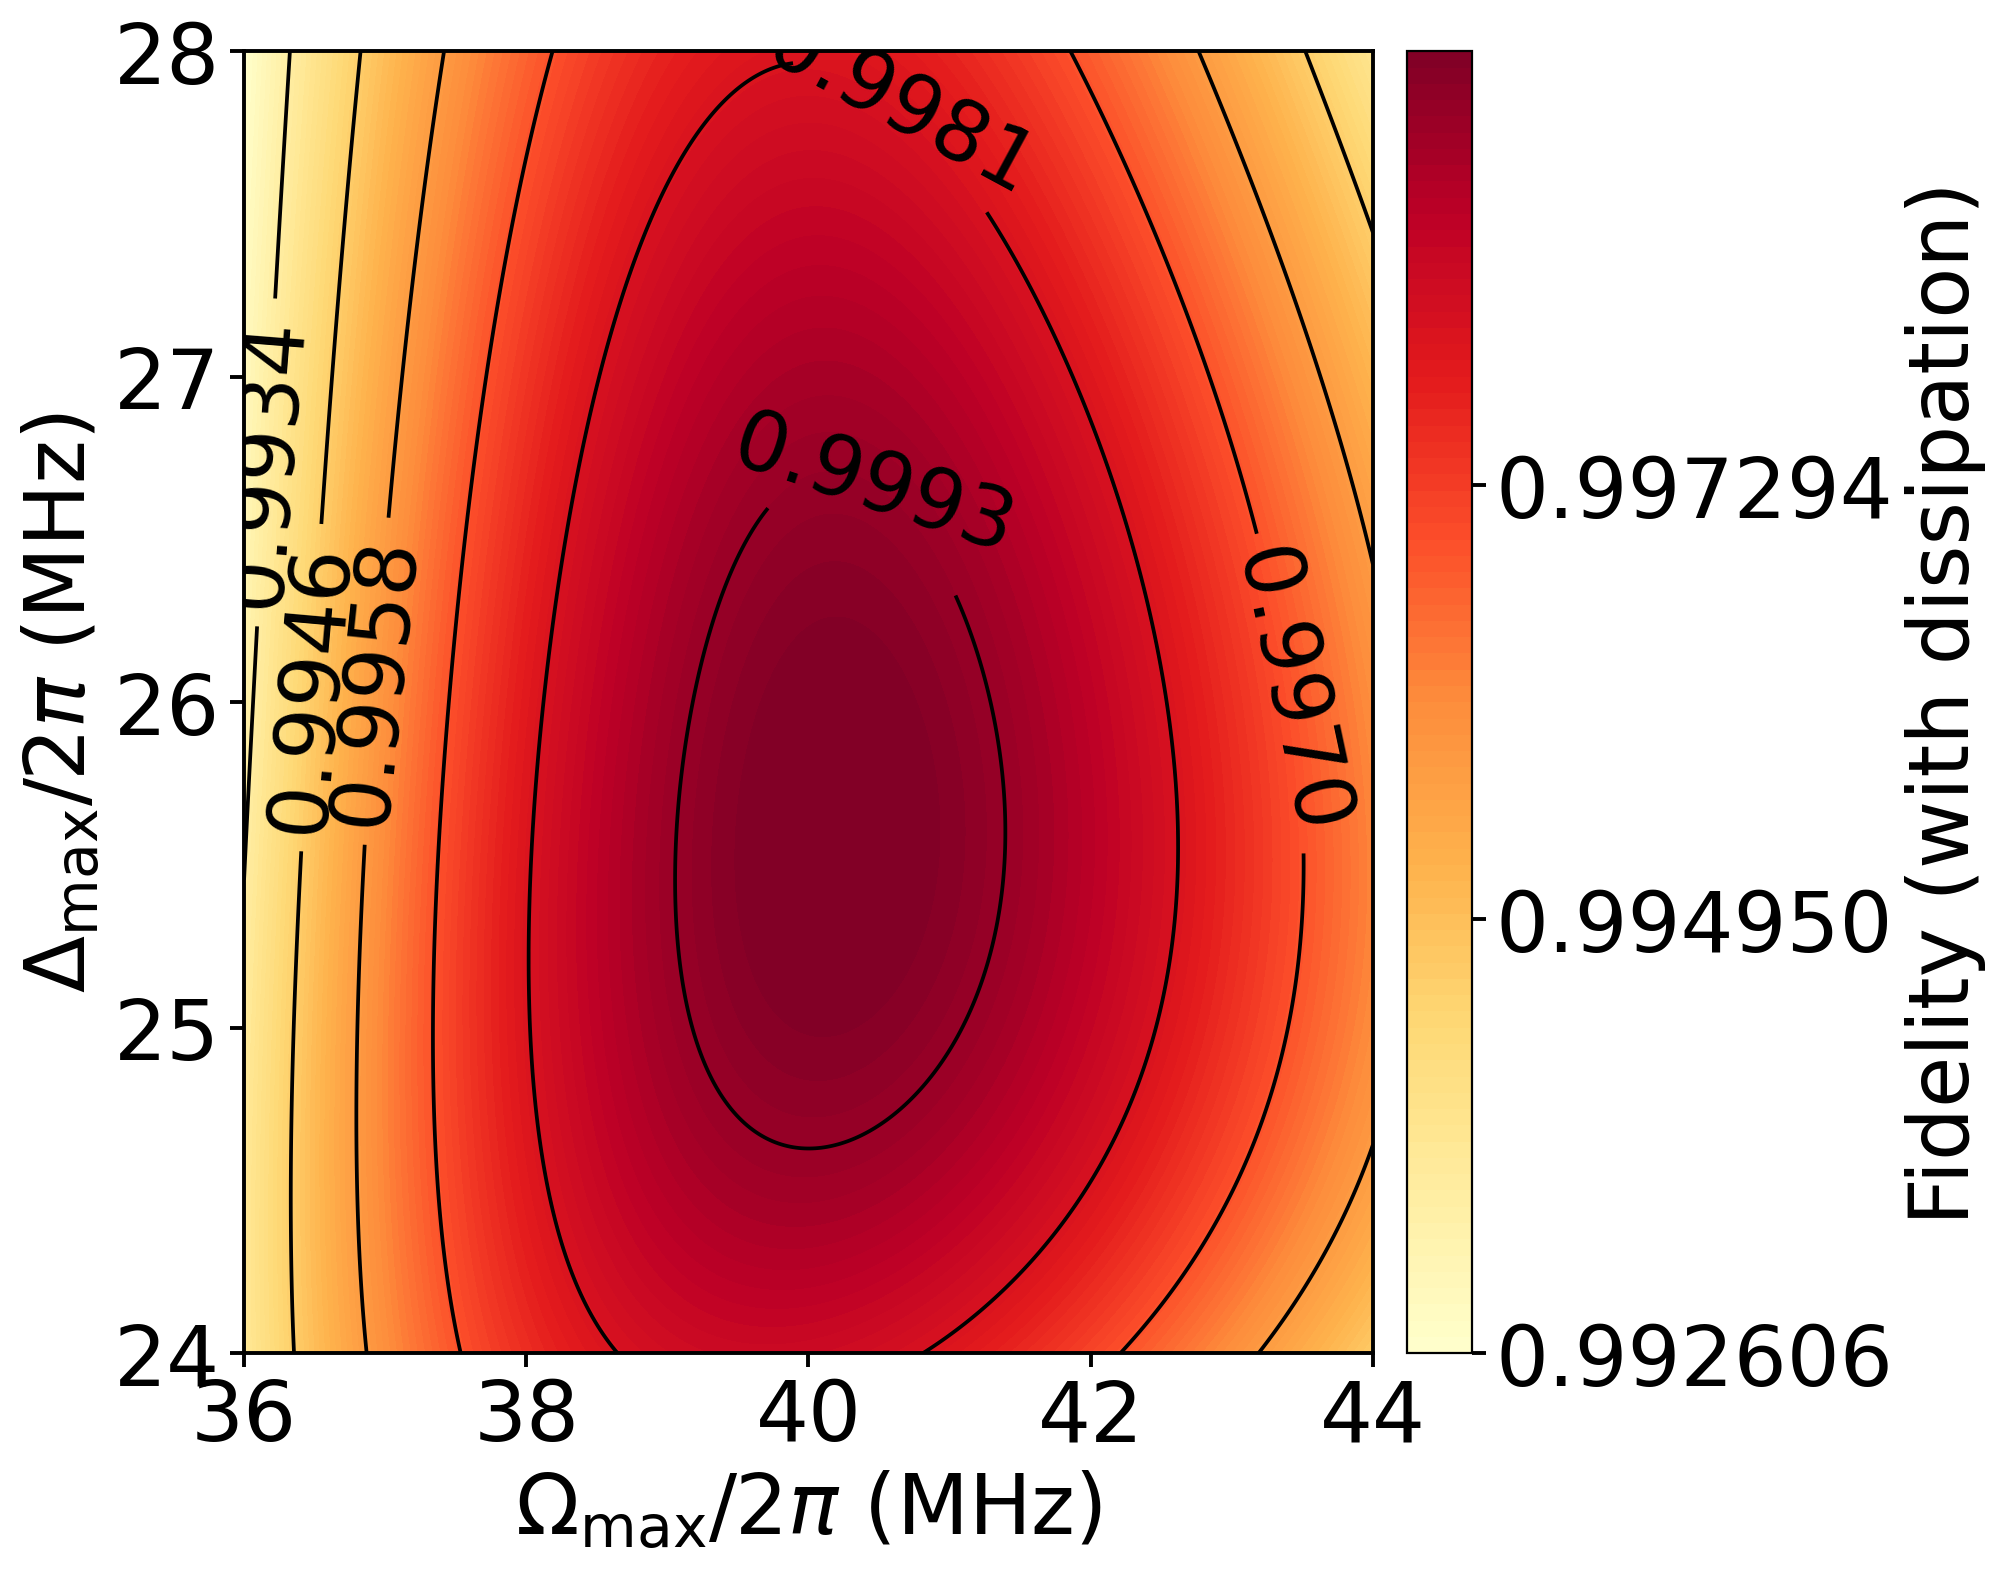

图已保存: tetrahedron_W4_Omega_Delta_Lindblad.png
最优参数: Omega=40.17 MHz, Delta=25.58 MHz, F=0.99971651


In [6]:
# -*- coding: utf-8 -*-
"""
4 比特 Ω-Δ 鲁棒性：完整 Lindblad 主方程版（Strang 分裂）
主方程: dr = -i[H,ρ] + Σ_k (L_k ρ L_k† - ½{L_k†L_k, ρ})
"""
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import expm
import matplotlib.ticker as mticker

USE_DISSIPATION = True
N_STEPS = 1000
SAVE_DATA = True

FS_LAB, FS_TCK = 30, 30
FS_CLABEL = 30
FIG_W, FIG_H = 10.0, 8.0

DATA_PATH = "tetrahedron_W4_Omega_Delta_data_Lindblad.npz"
FIG_PATH = "tetrahedron_W4_Omega_Delta_Lindblad.png"

# ==================== 与 4比特W.txt 完全一致的参数 ====================
Omega0   = 2.0 * np.pi * 100.0
TAU_TOT  = 227.91
OMMmax   = 0.4017
DE0max   = 0.2558
sR_dim   = 23.76
sD_dim   = 41.51
PF       = 0.5
V0_dim   = 5.2799

best_params = {
    "t_gate": TAU_TOT / Omega0,
    "sR": sR_dim / Omega0,
    "sD": sD_dim / Omega0,
    "Omega_max": OMMmax * Omega0,
    "D0": DE0max * Omega0,
}
V0 = V0_dim * Omega0
gamma_r = 1.0 / 540.0
Gamma_spont = gamma_r / 16.0
Gamma_deph  = 7.0 * gamma_r / 8.0

states = [q1 + q2 + q3 + q4
          for q1 in "01r" for q2 in "01r" for q3 in "01r" for q4 in "01r"]
dim = len(states)
si = {s: i for i, s in enumerate(states)}
nr = np.array([s.count("r") for s in states], dtype=float)

pairs = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
int_rel = np.zeros(dim)
for i, s in enumerate(states):
    rm = np.array([c == "r" for c in s])
    for a, b in pairs:
        if rm[a] and rm[b]:
            int_rel[i] += 1.0

ci, cj = [], []
for i, s in enumerate(states):
    for p in range(4):
        if s[p] == "1":
            ci.append(i); cj.append(si[s[:p] + "r" + s[p + 1:]])
        elif s[p] == "r":
            ci.append(i); cj.append(si[s[:p] + "1" + s[p + 1:]])
ci = np.array(ci); cj = np.array(cj)

fm = np.zeros(dim, dtype=int)
for s, idx in si.items():
    fm[idx] = si[s.replace("0", "_").replace("1", "0").replace("_", "1")]

i1111 = si["1111"]
w_states = ["1000", "0100", "0010", "0001"]
iW = np.array([si[s] for s in w_states], dtype=int)

# ==================== Lindblad 跳跃算符 ====================
sigma_0r = [np.zeros((dim, dim), dtype=complex) for _ in range(4)]
sigma_1r = [np.zeros((dim, dim), dtype=complex) for _ in range(4)]
mr = [np.zeros(dim, dtype=float) for _ in range(4)]
for k in range(4):
    for i, s in enumerate(states):
        if s[k] == "r":
            mr[k][i] = 1.0
            sigma_0r[k][si[s[:k] + "0" + s[k + 1:]], i] = np.sqrt(Gamma_spont)
            sigma_1r[k][si[s[:k] + "1" + s[k + 1:]], i] = np.sqrt(Gamma_spont)
mr_mat = [np.diag(mr[k]) for k in range(4)]

# ==================== 脉冲 ====================
def pulse_physical(t, p, omega_scale=1.0, delta_scale=1.0):
    tt = p["t_gate"]
    tpi = PF * tt
    tm = tpi / 2.0 if t < tpi else tpi + (tt - tpi) / 2.0
    xR = (t - tm) / p["sR"]
    xD = (t - tm) / p["sD"]
    O = (-p["Omega_max"] * omega_scale * np.sqrt(2 * np.e)
         * xR * np.exp(-(xR ** 2)))
    D = p["D0"] * delta_scale * np.e * xD ** 2 * np.exp(-(xD ** 2))
    return O, D

def build_H(O, D):
    H = np.zeros((dim, dim), dtype=complex)
    np.fill_diagonal(H, nr * D + int_rel * V0)
    H[ci, cj] = O / 2.0
    return H

# ==================== 完整 Lindblad 跳跃 ====================
def apply_diss(rho, dt):
    jump = np.zeros_like(rho)
    anti = np.zeros_like(rho)
    for k in range(4):
        jump += (sigma_0r[k] @ rho @ sigma_0r[k].conj().T
                 + sigma_1r[k] @ rho @ sigma_1r[k].conj().T)
        LdL_0 = sigma_0r[k].conj().T @ sigma_0r[k]
        LdL_1 = sigma_1r[k].conj().T @ sigma_1r[k]
        anti += LdL_0 @ rho + rho @ LdL_0 + LdL_1 @ rho + rho @ LdL_1
        mk = mr_mat[k]
        jump += Gamma_deph * (mk @ rho @ mk)
        anti += Gamma_deph * (mk @ rho + rho @ mk)
    rho[:] = rho + dt * (jump - 0.5 * anti)

def sim_dm(p, interaction, dO=0.0, dD=0.0, N_steps=N_STEPS):
    omega_scale = 1.0 + dO / 100.0
    delta_scale = 1.0 + dD / 100.0
    tt = p["t_gate"]
    dt = tt / N_steps
    dt_half = dt / 2.0
    n_half = N_steps // 2
    rho = np.zeros((dim, dim), dtype=complex)
    rho[i1111, i1111] = 1.0
    for phase in range(2):
        if phase == 1:
            rho = rho[np.ix_(fm, fm)]
        start = phase * n_half
        for i in range(start, start + n_half):
            t_mid = (i + 0.5) * dt
            O, D = pulse_physical(t_mid, p, omega_scale, delta_scale)
            H = build_H(O, D)
            U = expm(-1j * H * dt_half)
            Ud = U.conj().T
            rho = U @ rho @ Ud
            apply_diss(rho, dt)
            rho = U @ rho @ Ud
            rho = 0.5 * (rho + rho.conj().T)
    return (np.sum(rho[np.ix_(iW, iW)]) / 4.0).real

# ==================== 主程序 ====================
sim_func = sim_dm if USE_DISSIPATION else None
label = "with dissipation" if USE_DISSIPATION else "no dissipation"

print("=== Validation ===")
F_diss = sim_dm(best_params, V0, N_steps=N_STEPS)
print(f"F_diss = {F_diss:.8f}")
F_hp = F_diss
print(f"Target F>=0.998: {'OK' if F_hp >= 0.998 else 'NOT MET'}")

conv_factor = 1 / (2 * np.pi)
Omega_opt_MHz = best_params["Omega_max"] * conv_factor
Delta_opt_MHz = best_params["D0"] * conv_factor

SPAN_PCT = 10.0
NPT_AX = 5
def adaptive_int_axis(center_MHz, span_pct=SPAN_PCT, npt=NPT_AX):
    c = int(round(center_MHz))
    half = center_MHz * span_pct / 100.0
    step = max(1, int(round(2 * half / (npt - 1))))
    m = npt // 2
    return np.array([c + k * step for k in range(-m, npt - m)], dtype=float)

Omega_values_MHz = adaptive_int_axis(Omega_opt_MHz)
Delta_values_MHz = adaptive_int_axis(Delta_opt_MHz)
print(f"\nΩ0/2π = {Omega0 * conv_factor:.1f} MHz, "
      f"最优 Omega_max = {Omega_opt_MHz:.2f} MHz, "
      f"最优 Delta_0 = {Delta_opt_MHz:.2f} MHz, "
      f"t_gate = {best_params['t_gate']:.4f} µs")
print("Ω 坐标 (MHz):", Omega_values_MHz.astype(int))
print("Δ 坐标 (MHz):", Delta_values_MHz.astype(int))

data_path = DATA_PATH
grid = None
if SAVE_DATA and Path(data_path).exists():
    cached = np.load(data_path)
    if (np.allclose(cached["omega_MHz"], Omega_values_MHz)
            and np.allclose(cached["delta_MHz"], Delta_values_MHz)):
        grid = cached["fidelity"]
        print(f"读取已有网格数据: {data_path}")

if grid is None:
    grid = np.zeros((len(Omega_values_MHz), len(Delta_values_MHz)))
    t0 = time.time()
    for i, omega_mhz in enumerate(Omega_values_MHz):
        dO = (omega_mhz / Omega_opt_MHz - 1.0) * 100.0
        for j, delta_mhz in enumerate(Delta_values_MHz):
            dD = (delta_mhz / Delta_opt_MHz - 1.0) * 100.0
            grid[i, j] = sim_func(best_params, V0, dO, dD)
        elapsed = time.time() - t0
        remaining = elapsed / (i + 1) * (len(Omega_values_MHz) - i - 1)
        print(f"  Row {i + 1}/{len(Omega_values_MHz)}  {elapsed:.0f}s  ETA {remaining:.0f}s")
    print("扫描完成")
    print(f"网格最低值 F_min = {grid.min():.6f}")
    print(f"网格最高值 F_max = {grid.max():.6f}")
    if SAVE_DATA:
        np.savez(data_path, omega_MHz=Omega_values_MHz,
                 delta_MHz=Delta_values_MHz, fidelity=grid)

# ==================== 绘图（横轴 Ω、纵轴 Δ） ====================
from scipy.interpolate import RectBivariateSpline
dense_omega = np.linspace(Omega_values_MHz[0], Omega_values_MHz[-1], 400)
dense_delta = np.linspace(Delta_values_MHz[0], Delta_values_MHz[-1], 400)
interp = RectBivariateSpline(Omega_values_MHz, Delta_values_MHz, grid,
                             kx=min(3, len(Omega_values_MHz)-1),
                             ky=min(3, len(Delta_values_MHz)-1), s=0)
dense_grid = np.clip(interp(dense_omega, dense_delta),
                     grid.min(), grid.max())

def clabel_once_per_level(ax, cs, fmt="%.4f", fontsize=FS_CLABEL, colors="black"):
    levels_ok, pos = [], []
    for lev, segs in zip(cs.levels, cs.allsegs):
        if not len(segs):
            continue
        seg = max(segs, key=len)
        k = len(seg) // 2
        levels_ok.append(float(lev))
        pos.append((float(seg[k, 0]), float(seg[k, 1])))
    if levels_ok:
        ax.clabel(cs, levels=levels_ok, manual=pos, fmt=fmt,
                  fontsize=fontsize, colors=colors, inline=True)
    return len(levels_ok)

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
fill_levels = np.linspace(grid.min(), grid.max(), 81)
cf = ax.contourf(dense_omega, dense_delta, dense_grid.T, levels=fill_levels,
                 cmap="YlOrRd", extend="neither")

vmin, vmax = float(grid.min()), float(grid.max())
if vmax - vmin < 1e-9:
    vmax = vmin + 1e-9
line_levels = vmin + (vmax - vmin) * np.linspace(0.12, 0.95, 6)
line_levels = np.unique(line_levels[(line_levels > vmin) & (line_levels < vmax)])
if len(line_levels) > 0:
    cs = ax.contour(dense_omega, dense_delta, dense_grid.T, levels=line_levels,
                    colors="black", linewidths=1.35)
    clabel_once_per_level(ax, cs, fmt="%.4f", fontsize=FS_CLABEL, colors="black")

# ===== 颜色划分不变，色标只显示 4 个自适应数值 =====
cb_ticks = np.linspace(vmin, vmax, 4).round(6)
cbar = plt.colorbar(cf, ax=ax, pad=0.025, ticks=cb_ticks)
cbar.set_label("Fidelity (with dissipation)", fontsize=FS_LAB)
cbar.ax.tick_params(labelsize=FS_TCK, width=1.4, length=5)

ax.set_xlabel(r'$\Omega_{\max}/2\pi$ (MHz)', fontsize=FS_LAB)
ax.set_ylabel(r'$\Delta_{\max}/2\pi$ (MHz)', fontsize=FS_LAB)
ax.set_xlim(Omega_values_MHz[0], Omega_values_MHz[-1])
ax.set_ylim(Delta_values_MHz[0], Delta_values_MHz[-1])
ax.set_xticks(Omega_values_MHz)
ax.set_yticks(Delta_values_MHz)
ax.set_xticklabels([f"{int(round(v))}" for v in Omega_values_MHz])
ax.set_yticklabels([f"{int(round(v))}" for v in Delta_values_MHz])
ax.tick_params(axis="both", which="major", labelsize=FS_TCK, width=1.4, length=5)
for spine in ax.spines.values():
    spine.set_linewidth(1.4)
plt.tight_layout()
fig.savefig(FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()
print(f"图已保存: {FIG_PATH}")
print(f"最优参数: Omega={Omega_opt_MHz:.2f} MHz, Delta={Delta_opt_MHz:.2f} MHz, F={F_hp:.8f}")

鲁棒性参数：Ω = 29.6977 MHz, Δ0 = 17.5051 MHz
正在粗扫描最大保真度位置...
粗扫描最大值：Ω ≈ 30 MHz, Δ0 ≈ 18 MHz, F = 0.99970072
Ω=28 MHz, Δ=16 MHz, F=0.99585012
Ω=28 MHz, Δ=17 MHz, F=0.99820672
Ω=28 MHz, Δ=18 MHz, F=0.99637775
Ω=28 MHz, Δ=19 MHz, F=0.99294911
Ω=28 MHz, Δ=20 MHz, F=0.98959564
Ω=29 MHz, Δ=16 MHz, F=0.99547162
Ω=29 MHz, Δ=17 MHz, F=0.99934737
Ω=29 MHz, Δ=18 MHz, F=0.99861409
Ω=29 MHz, Δ=19 MHz, F=0.99587829
Ω=29 MHz, Δ=20 MHz, F=0.99286701
Ω=30 MHz, Δ=16 MHz, F=0.99326279
Ω=30 MHz, Δ=17 MHz, F=0.99889885
Ω=30 MHz, Δ=18 MHz, F=0.99947356
Ω=30 MHz, Δ=19 MHz, F=0.99759771
Ω=30 MHz, Δ=20 MHz, F=0.99504378
Ω=31 MHz, Δ=16 MHz, F=0.98975670
Ω=31 MHz, Δ=17 MHz, F=0.99722108
Ω=31 MHz, Δ=18 MHz, F=0.99915246
Ω=31 MHz, Δ=19 MHz, F=0.99815589
Ω=31 MHz, Δ=20 MHz, F=0.99604756
Ω=32 MHz, Δ=16 MHz, F=0.98570923
Ω=32 MHz, Δ=17 MHz, F=0.99488032
Ω=32 MHz, Δ=18 MHz, F=0.99804051
Ω=32 MHz, Δ=19 MHz, F=0.99778857
Ω=32 MHz, Δ=20 MHz, F=0.99598945


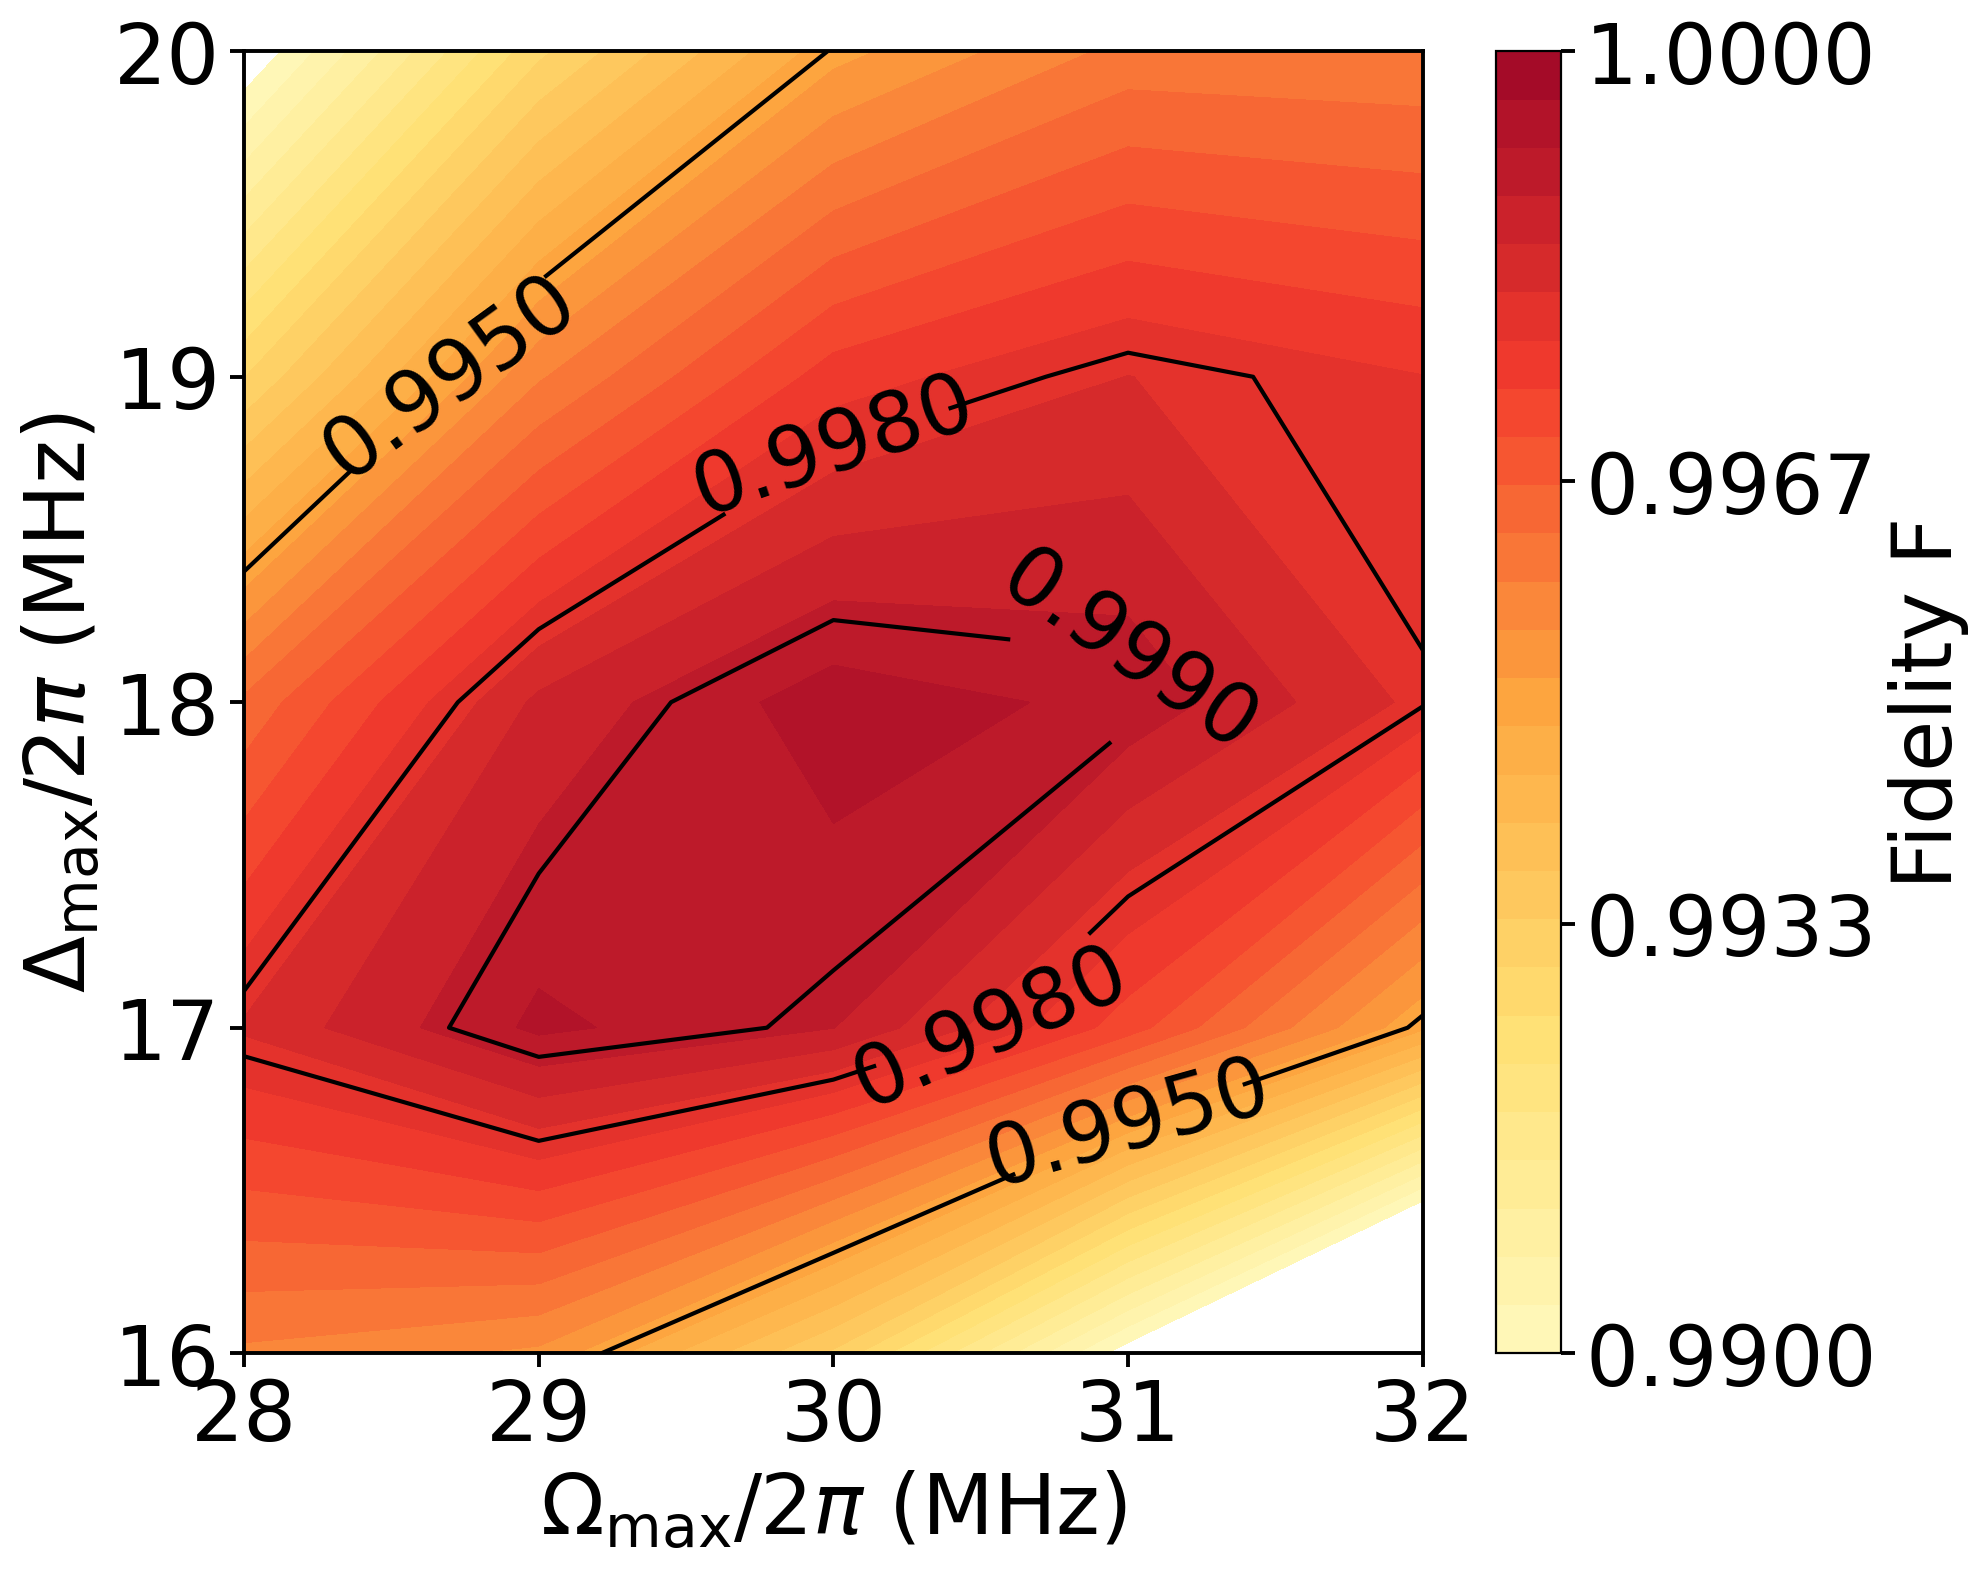

In [7]:
import numpy as np                      # 数值计算库
from itertools import product           # 生成基矢
import matplotlib.pyplot as plt         # 绘图
from matplotlib.colors import LinearSegmentedColormap, Normalize

# ==================== 无量纲参数（能量单位 Ω10，时间单位 1/Ω10） ====================
Omega10   = 2*np.pi*100.0
Omega_max = 0.2969771
t_gate    = 290.9825033647375
gamma_r   = 1.0/540.0
Gamma     = gamma_r/Omega10
Gamma_spont = Gamma/16
Gamma_deph  = 7*Gamma/8
N_step    = 600

# ==================== 无能级交叉脉冲的无量纲参数 ====================
V0 = 3.9167245
D0 = 0.1750508
sD = 60.67294751009421
sR = 32.55720053835801
pf = 0.500

# ==================== 全 Hilbert 空间（2 原子，9 维） ====================
N = 2
st = [''.join(p) for p in product('01r', repeat=N)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)

C = np.zeros((d, d), dtype=complex)
for s, i in idx.items():
    for a in range(N):
        if s[a] == '1':   s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r': s2 = s[:a]+'1'+s[a+1:]
        else: continue
        C[idx[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
E_i = np.array([V0*(s.count('r')*(s.count('r')-1)//2) for s in st], float)
g_perm = np.array([idx[s.replace('0','_').replace('1','0').replace('_','1')]
                   for s in st])

spont = []
for a in range(N):
    for ch in '01':
        src = np.array([i for s, i in idx.items() if s[a] == 'r'])
        dst = np.array([idx[s[:a]+ch+s[a+1:]] for s, i in idx.items() if s[a] == 'r'])
        spont.append((src, dst))
D_deph = np.zeros((d, d))
for a in range(N):
    m = np.array([1.0 if s[a] == 'r' else 0.0 for s in st])
    D_deph += np.outer(m, m)
D_deph *= Gamma_deph
ldl = Gamma * n_r

psi0 = np.zeros(d, complex); psi0[idx['11']] = 1.0
psiT = np.zeros(d, complex)
psiT[idx['01']] = 1/np.sqrt(2); psiT[idx['10']] = 1/np.sqrt(2)

# ==================== 含耗散保真度 ====================
t  = (np.arange(N_step)+0.5)*t_gate/N_step
t_pi = pf*t_gate
tm = np.where(t < t_pi, t_pi/2, t_pi + (t_gate - t_pi)/2)
xR = (t-tm)/sR; xD = (t-tm)/sD
base_Om = -Omega_max*np.sqrt(2*np.e)*xR*np.exp(-xR**2)
base_De = D0*np.e*xD**2*np.exp(-xD**2)
dt  = t_gate/N_step
n_pi = int(round(pf*N_step))
rr  = np.arange(d)
anti = ldl[:, None] + ldl[None, :]

def fidelity(Om_scale=1.0, D0_scale=1.0):
    H = (base_Om*Om_scale)[:, None, None]*C[None]
    H[:, rr, rr] += (base_De*D0_scale)[:, None]*n_r[None] + E_i[None]
    w, v = np.linalg.eigh(H)
    Uh = v*np.exp(-1j*w*dt/2)[:, None, :] @ np.swapaxes(v.conj(), 1, 2)
    rho = np.outer(psi0, psi0.conj())
    for n in range(N_step):
        rho = Uh[n] @ rho @ Uh[n].conj().T
        jump = D_deph*rho
        for src, dst in spont:
            jump[np.ix_(dst, dst)] += Gamma_spont*rho[np.ix_(src, src)]
        rho = rho + dt*(jump - 0.5*anti*rho)
        rho = Uh[n] @ rho @ Uh[n].conj().T
        if n == n_pi - 1:
            rho = rho[np.ix_(g_perm, g_perm)]
    return np.real(psiT.conj() @ rho @ psiT)

# ==================== Ω–Δ 自适应取值 ====================
N_COARSE = 21
N_COORD = 5
SEARCH_FRAC = 0.10

Omega0_MHz = Omega_max*Omega10/(2*np.pi)
D0_MHz = D0*Omega10/(2*np.pi)
coarse_Omega_MHz = np.linspace((1-SEARCH_FRAC)*Omega0_MHz,
                               (1+SEARCH_FRAC)*Omega0_MHz, N_COARSE)
coarse_Delta_MHz = np.linspace((1-SEARCH_FRAC)*D0_MHz,
                               (1+SEARCH_FRAC)*D0_MHz, N_COARSE)
coarse_grid = np.empty((N_COARSE, N_COARSE))

print(f"鲁棒性参数：Ω = {Omega0_MHz:.4f} MHz, Δ0 = {D0_MHz:.4f} MHz")
print("正在粗扫描最大保真度位置...")
for i, Om_MHz in enumerate(coarse_Omega_MHz):
    for j, De_MHz in enumerate(coarse_Delta_MHz):
        coarse_grid[i, j] = fidelity(Om_MHz/Omega0_MHz,
                                     De_MHz/D0_MHz)

i_max, j_max = np.unravel_index(np.nanargmax(coarse_grid), coarse_grid.shape)
Omega_peak_MHz = coarse_Omega_MHz[i_max]
Delta_peak_MHz = coarse_Delta_MHz[j_max]
Omega_center_MHz = int(np.rint(Omega_peak_MHz))
Delta_center_MHz = int(np.rint(Delta_peak_MHz))
Omega_step_MHz = max(1, int(np.rint(2*SEARCH_FRAC*Omega0_MHz/(N_COORD-1))))
Delta_step_MHz = max(1, int(np.rint(2*SEARCH_FRAC*D0_MHz/(N_COORD-1))))
coord_offset = np.arange(N_COORD, dtype=int) - (N_COORD-1)//2
Omega_values_MHz = Omega_center_MHz + coord_offset*Omega_step_MHz
Delta_values_MHz = Delta_center_MHz + coord_offset*Delta_step_MHz
Omega_scales = Omega_values_MHz/Omega0_MHz
Delta_scales = Delta_values_MHz/D0_MHz
grid = np.empty((N_COORD, N_COORD))

print(f"粗扫描最大值：Ω ≈ {Omega_center_MHz:d} MHz, "
      f"Δ0 ≈ {Delta_center_MHz:d} MHz, F = {coarse_grid[i_max, j_max]:.8f}")
for i, Om_scale in enumerate(Omega_scales):
    for j, D_scale in enumerate(Delta_scales):
        grid[i, j] = fidelity(Om_scale, D_scale)
        print(f"Ω={Omega_values_MHz[i]:d} MHz, "
              f"Δ={Delta_values_MHz[j]:d} MHz, F={grid[i, j]:.8f}")

F0 = fidelity(1.0, 1.0)
# ==================== 画鲁棒性等高线图 ====================
cmap_ref = LinearSegmentedColormap.from_list('ref_yor', [
    (1.000, 0.976, 0.737),
    (1.000, 0.878, 0.451),
    (0.992, 0.651, 0.247),
    (0.953, 0.231, 0.176),
    (0.624, 0.031, 0.157),
])
FS_LAB, FS_TCK = 30, 30

LO, HI = 0.985, 1.0                    # 色标窗口
CLINES = [0.995, 0.998, 0.999, 0.9995]   # 等高线取值
# ===== 自适应色标：按 grid 实际数据范围，向下取整到 3 位小数 =====
_data_min = float(np.floor(grid.min() * 1000) / 1000)
LO = max(_data_min, 0.99)
HI = 1.0

fig, ax = plt.subplots(figsize=(10.0, 8.0))

cf = ax.contourf(Omega_values_MHz, Delta_values_MHz, grid.T,
                 levels=np.linspace(LO, HI, 28),
                 cmap=cmap_ref, norm=Normalize(LO, HI), extend='neither')

cs = ax.contour(Omega_values_MHz, Delta_values_MHz, grid.T,
                levels=CLINES, colors='black', linewidths=1.5)
ax.clabel(cs, fmt='%.4f', fontsize=30, colors='black')

cbar = plt.colorbar(cf, ax=ax, ticks=np.linspace(LO, HI, 4).round(4))
cbar.set_label('Fidelity F', fontsize=30)
cbar.ax.tick_params(labelsize=FS_TCK, width=1.4, length=5)

ax.set_xlabel(r'$\Omega_{\max}/2\pi$ (MHz)', fontsize=FS_LAB)
ax.set_ylabel(r'$\Delta_{\max}/2\pi$ (MHz)', fontsize=FS_LAB)
ax.tick_params(axis='both', labelsize=FS_TCK, width=1.4, length=5)
for sp in ax.spines.values():
    sp.set_linewidth(1.4)

ax.set_xlim(Omega_values_MHz[0], Omega_values_MHz[-1])
ax.set_ylim(Delta_values_MHz[0], Delta_values_MHz[-1])
ax.set_xticks(Omega_values_MHz)
ax.set_yticks(Delta_values_MHz)

plt.tight_layout()
plt.savefig('2比特ΔΩ_鲁棒性图.png', dpi=200)
plt.show()

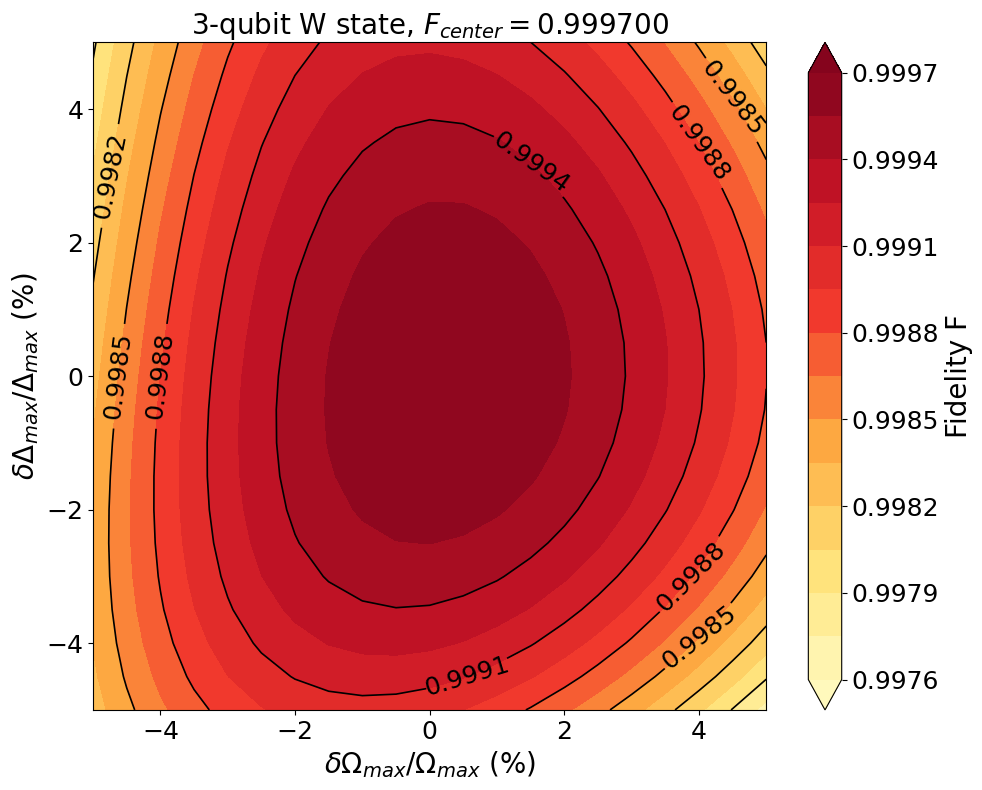

In [1]:
%matplotlib inline
# -*- coding: utf-8 -*-
"""
三比特 W 态鲁棒性：完整 Lindblad 主方程。

"""

import os
import time
from collections import Counter
from itertools import product

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

try:
    from numba import njit, prange
except ImportError as exc:
    raise ImportError(
    ) from exc


# ==================== 物理参数 ====================
Omega10 = 2 * np.pi * 100.0
gamma_r = 1.0 / 540.0

TAU_TOT = 254.64804469273741
OM1max = 0.356747
DE1max = 0.22176485870975582
sR = 27.050279329608937
sD = 47.3815270018622
PF = 0.501
V0 = 4.319068724444445

Gamma = gamma_r / Omega10
Gamma_spont = Gamma / 16.0
Gamma_deph = 7.0 * Gamma / 8.0

N = 3
LOCAL_PAIRS = tuple(product("01r", repeat=2))
states = ["".join(p) for p in product("01r", repeat=N)]
state_index = {s: i for i, s in enumerate(states)}
d = len(states)
n_r = np.array([s.count("r") for s in states], dtype=np.int64)
interaction_energy = V0 * n_r * (n_r - 1) / 2


# ==================== 对称 Liouville 空间 ====================
def _signature(a, b):
    """(a,b) 在同时置换三个原子下的轨道标签。"""
    counts = Counter(zip(a, b))
    return tuple(counts[p] for p in LOCAL_PAIRS)


signatures = []
representatives = []
orbit_index = {}
for i, a in enumerate(states):
    for j, b in enumerate(states):
        key = _signature(a, b)
        if key not in orbit_index:
            orbit_index[key] = len(signatures)
            signatures.append(key)
            representatives.append((i, j))

M = len(signatures)  # N=3 时为 165，而不是 729

# L(t) = A0 + Omega(t)*AO + Delta(t)*AD
A0_diss = np.zeros((M, M), dtype=np.complex128)
A0_unitary = np.zeros_like(A0_diss)
AO = np.zeros_like(A0_diss)
AD = np.zeros_like(A0_diss)

for row, (i, j) in enumerate(representatives):
    a, b = states[i], states[j]

    # -i[Err, rho] 和 -i Delta[Dr, rho]
    h0 = -1j * (interaction_energy[i] - interaction_energy[j])
    A0_unitary[row, row] += h0
    A0_diss[row, row] += h0
    AD[row, row] += -1j * (n_r[i] - n_r[j])

    # 自发辐射反对易项；两个通道 r->0 和 r->1
    A0_diss[row, row] += -Gamma_spont * (n_r[i] + n_r[j])

    # 纯退相位。只有 bra/ket 的 r 占据不同时产生衰减。
    r_mismatch = sum((x == "r") != (y == "r") for x, y in zip(a, b))
    A0_diss[row, row] += -0.5 * Gamma_deph * r_mismatch

    for atom in range(N):
        # -i Omega (Cc rho - rho Cc)，Cc 的非零矩阵元均为 1/2
        if a[atom] in "1r":
            flipped = "r" if a[atom] == "1" else "1"
            aa = a[:atom] + flipped + a[atom + 1 :]
            AO[row, orbit_index[_signature(aa, b)]] += -0.5j
        if b[atom] in "1r":
            flipped = "r" if b[atom] == "1" else "1"
            bb = b[:atom] + flipped + b[atom + 1 :]
            AO[row, orbit_index[_signature(a, bb)]] += 0.5j

        # sum_ch L_(atom,ch) rho L_(atom,ch)^dagger
        for channel in "01":
            if a[atom] == channel and b[atom] == channel:
                aa = a[:atom] + "r" + a[atom + 1 :]
                bb = b[:atom] + "r" + b[atom + 1 :]
                col = orbit_index[_signature(aa, bb)]
                A0_diss[row, col] += Gamma_spont


# 三个矩阵使用同一份 CSR 稀疏结构，便于 JIT 内一次完成 matvec。
union_mask = (A0_diss != 0) | (A0_unitary != 0) | (AO != 0) | (AD != 0)
indptr = np.zeros(M + 1, dtype=np.int64)
indices_list = []
v0_diss_list = []
v0_unitary_list = []
vo_list = []
vd_list = []
for row in range(M):
    cols = np.flatnonzero(union_mask[row])
    indices_list.extend(cols)
    v0_diss_list.extend(A0_diss[row, cols])
    v0_unitary_list.extend(A0_unitary[row, cols])
    vo_list.extend(AO[row, cols])
    vd_list.extend(AD[row, cols])
    indptr[row + 1] = len(indices_list)

indices = np.asarray(indices_list, dtype=np.int64)
V0_DISS = np.asarray(v0_diss_list, dtype=np.complex128)
V0_UNITARY = np.asarray(v0_unitary_list, dtype=np.complex128)
VO = np.asarray(vo_list, dtype=np.complex128)
VD = np.asarray(vd_list, dtype=np.complex128)

# 初态 |111><111|
x_initial = np.zeros(M, dtype=np.complex128)
x_initial[orbit_index[_signature("111", "111")]] = 1.0

# F=<W|rho|W> 的线性权重
target_states = ("001", "010", "100")
fidelity_weight = np.zeros(M, dtype=np.float64)
for a in target_states:
    for b in target_states:
        fidelity_weight[orbit_index[_signature(a, b)]] += 1.0 / 3.0

# pi_g 脉冲：同时交换每个原子的 |0> 和 |1>
swap01 = str.maketrans("01", "10")
permuted_state = np.array(
    [state_index[s.translate(swap01)] for s in states], dtype=np.int64
)
pi_map = np.empty(M, dtype=np.int64)
for row, (i, j) in enumerate(representatives):
    pi_map[row] = orbit_index[
        _signature(states[permuted_state[i]], states[permuted_state[j]])
    ]


def _pulse_arrays(dt):
    """预先计算全部 RK4 节点上的无量纲脉冲值。"""
    n_steps = int(round(TAU_TOT / dt))
    # 与原程序一致：实际步长保持为传入的 dt。
    t = np.arange(n_steps, dtype=np.float64) * dt
    tau_pi = PF * TAU_TOT

    def pulse(tau):
        tm = np.where(
            tau <= tau_pi,
            tau_pi / 2,
            tau_pi + (TAU_TOT - tau_pi) / 2,
        )
        x_r = (tau - tm) / sR
        x_d = (tau - tm) / sD
        om = -np.sqrt(2 * np.e) * x_r * np.exp(-(x_r**2))
        de = np.e * x_d**2 * np.exp(-(x_d**2))
        return om, de

    om0, de0 = pulse(t)
    omh, deh = pulse(t + dt / 2)
    om1, de1 = pulse(t + dt)
    n_pi = int(round(PF * n_steps))
    return om0, de0, omh, deh, om1, de1, n_pi


@njit(inline="always", fastmath=True)
def _matvec(out, x, omega, delta, ptr, cols, v0, vo, vd):
    for row in range(x.size):
        total = 0.0j
        for p in range(ptr[row], ptr[row + 1]):
            total += (v0[p] + omega * vo[p] + delta * vd[p]) * x[cols[p]]
        out[row] = total


@njit(parallel=True, fastmath=True, cache=False)
def _integrate_grid(
    omega_max,
    delta_max,
    dt,
    om0,
    de0,
    omh,
    deh,
    om1,
    de1,
    n_pi,
    ptr,
    cols,
    v0,
    vo,
    vd,
    x0,
    pmap,
    weight,
):
    count = omega_max.size
    result = np.empty(count, dtype=np.float64)

    # 每个扫描点完全独立，prange 会自动使用多个 CPU 核。
    for g in prange(count):
        x = x0.copy()
        k1 = np.empty_like(x)
        k2 = np.empty_like(x)
        k3 = np.empty_like(x)
        k4 = np.empty_like(x)
        tmp = np.empty_like(x)

        for n in range(om0.size):
            omax = omega_max[g]
            dmax = delta_max[g]

            _matvec(k1, x, om0[n] * omax, de0[n] * dmax,
                    ptr, cols, v0, vo, vd)
            for q in range(x.size):
                tmp[q] = x[q] + 0.5 * dt * k1[q]

            _matvec(k2, tmp, omh[n] * omax, deh[n] * dmax,
                    ptr, cols, v0, vo, vd)
            for q in range(x.size):
                tmp[q] = x[q] + 0.5 * dt * k2[q]

            _matvec(k3, tmp, omh[n] * omax, deh[n] * dmax,
                    ptr, cols, v0, vo, vd)
            for q in range(x.size):
                tmp[q] = x[q] + dt * k3[q]

            _matvec(k4, tmp, om1[n] * omax, de1[n] * dmax,
                    ptr, cols, v0, vo, vd)
            for q in range(x.size):
                x[q] += dt * (k1[q] + 2*k2[q] + 2*k3[q] + k4[q]) / 6.0

            if n == n_pi - 1:
                for q in range(x.size):
                    tmp[q] = x[pmap[q]]
                for q in range(x.size):
                    x[q] = tmp[q]

        f = 0.0
        for q in range(x.size):
            f += weight[q] * x[q].real
        result[g] = f

    return result


def fidelity(dO=0.0, dD=0.0, dt=0.10, diss=True):

    dO, dD = np.broadcast_arrays(
        np.asarray(dO, dtype=np.float64), np.asarray(dD, dtype=np.float64)
    )
    original_shape = dO.shape
    omega_max = np.ascontiguousarray(OM1max * (1.0 + dO.ravel() / 100.0))
    delta_max = np.ascontiguousarray(DE1max * (1.0 + dD.ravel() / 100.0))
    pulse_data = _pulse_arrays(float(dt))
    om0, de0, omh, deh, om1, de1, n_pi = pulse_data
    v0 = V0_DISS if diss else V0_UNITARY

    values = _integrate_grid(
        omega_max, delta_max, float(dt),
        om0, de0, omh, deh, om1, de1, n_pi,
        indptr, indices, v0, VO, VD,
        x_initial, pi_map, fidelity_weight,
    )
    return values.reshape(original_shape)


def scan_and_plot(points=21, span=5.0, dt=0.10, output_dir=None):
    """扫描正方形误差网格、保存数据并绘制等高线图。"""
    offsets = np.linspace(-span, span, points)
    DO, DD = np.meshgrid(offsets, offsets)

    t0 = time.perf_counter()
    grid = fidelity(DO, DD, dt=dt, diss=True)
    elapsed = time.perf_counter() - t0

    if output_dir is None:
        output_dir = os.getcwd()
    os.makedirs(output_dir, exist_ok=True)
    data_path = os.path.join(output_dir, "grid_3qubit_gd_fast.npy")
    figure_path = os.path.join(output_dir, "fig_3qubit_gd_pulse_fast.png")
    np.save(data_path, grid)

    vmin, vmax = float(grid.min()), float(grid.max())
    cmap = LinearSegmentedColormap.from_list("paper", [
        (1.000, 0.976, 0.737), (1.000, 0.878, 0.451),
        (0.992, 0.651, 0.247), (0.953, 0.231, 0.176),
        (0.780, 0.080, 0.150), (0.520, 0.015, 0.115),
    ])
    fill_levels = mticker.MaxNLocator(nbins=15).tick_values(vmin, vmax)
    line_levels = mticker.MaxNLocator(8).tick_values(vmin, vmax)
    line_levels = line_levels[(line_levels > vmin) & (line_levels < vmax)]

    fig, ax = plt.subplots(figsize=(10, 8))
    cf = ax.contourf(offsets, offsets, grid, levels=fill_levels,
                     cmap=cmap, extend="both")
    if line_levels.size:
        cs = ax.contour(offsets, offsets, grid, levels=line_levels,
                        colors="black", linewidths=1.2)
        ax.clabel(cs, fmt="%.4f", fontsize=18, colors="black")
    cbar = fig.colorbar(cf, ax=ax)
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Fidelity F", fontsize=20)
    ax.set_xlabel(r"$\delta\Omega_{max}/\Omega_{max}$ (%)", fontsize=20)
    ax.set_ylabel(r"$\delta\Delta_{max}/\Delta_{max}$ (%)", fontsize=20)
    center = grid[points // 2, points // 2] if points % 2 else np.nan
    ax.set_title(f"3-qubit W state, $F_{{center}}={center:.6f}$", fontsize=20)
    ax.tick_params(axis="both", labelsize=18)
    fig.tight_layout()
    fig.savefig(figure_path, dpi=200)

    return offsets, grid, fig


if __name__ == "__main__":
    scan_and_plot(points=21, span=5.0, dt=0.10)
    plt.show()


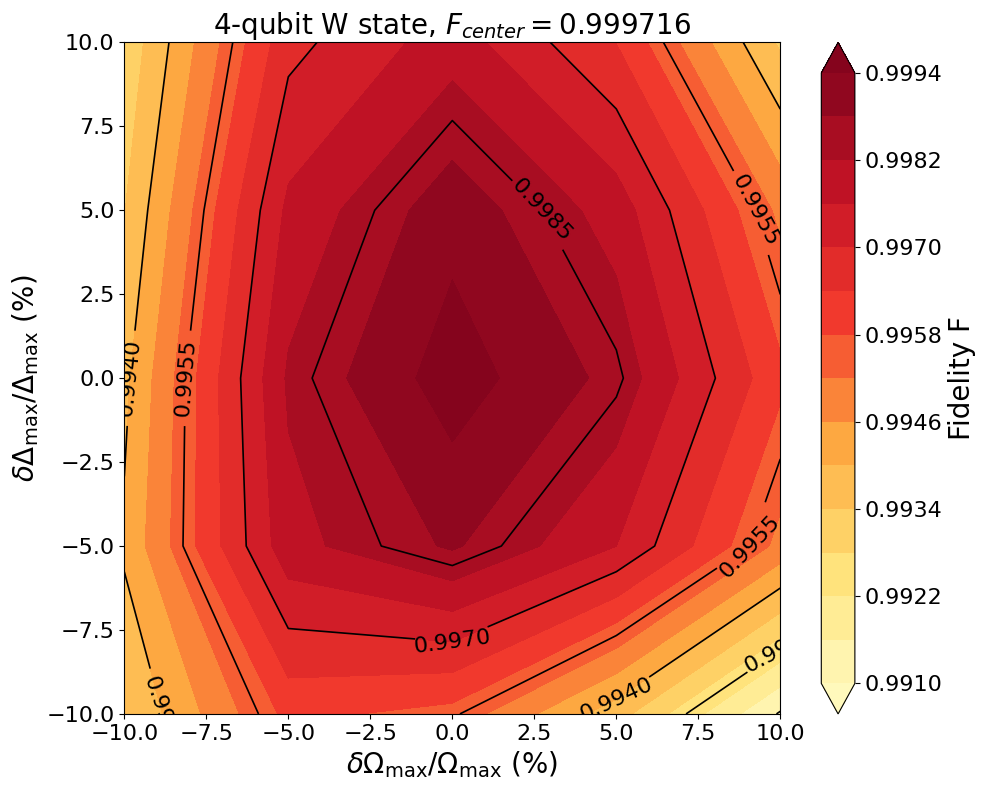

In [2]:
%matplotlib inline
# -*- coding: utf-8 -*-
"""
四比特 W 态鲁棒性：完整 Lindblad 主方程。

"""

import os
import time
from collections import Counter
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

try:
    from numba import njit, prange
except ImportError as exc:
    raise ImportError(

    ) from exc


# ==================== 参数 ====================
N_ATOMS = 4
Omega0 = 2.0 * np.pi * 100.0
TAU_TOT = 227.91
OMMmax = 0.4017
DE0max = 0.2558
sR = 23.76
sD = 41.51
PF = 0.5
V0 = 5.2799
gamma_r = 1.0 / 540.0
Gamma = gamma_r / Omega0
Gamma_spont = Gamma / 16.0
Gamma_deph = 7.0 * Gamma / 8.0

LOCAL_PAIRS = tuple(product("01r", repeat=2))
states = ["".join(p) for p in product("01r", repeat=N_ATOMS)]
state_index = {s: i for i, s in enumerate(states)}
dim = len(states)
n_r = np.array([s.count("r") for s in states], dtype=np.int64)
interaction_energy = V0 * n_r * (n_r - 1) / 2


# ==================== 置换对称 Liouville 空间 ====================
def _signature(a, b):
    """密度矩阵元 |a><b| 在同时置换所有原子下的轨道标签。"""
    counts = Counter(zip(a, b))
    return tuple(counts[p] for p in LOCAL_PAIRS)


signatures = []
representatives = []
orbit_index = {}
for i, a in enumerate(states):
    for j, b in enumerate(states):
        key = _signature(a, b)
        if key not in orbit_index:
            orbit_index[key] = len(signatures)
            signatures.append(key)
            representatives.append((i, j))

M = len(signatures)  # 四原子时为 495

# L(t) = A0 + Omega(t) AO + Delta(t) AD
A0_diss = np.zeros((M, M), dtype=np.complex128)
A0_unitary = np.zeros_like(A0_diss)
AO = np.zeros_like(A0_diss)
AD = np.zeros_like(A0_diss)

for row, (i, j) in enumerate(representatives):
    a, b = states[i], states[j]

    # Hamiltonian 的对角部分。
    h0 = -1j * (interaction_energy[i] - interaction_energy[j])
    A0_diss[row, row] += h0
    A0_unitary[row, row] += h0
    AD[row, row] += -1j * (n_r[i] - n_r[j])

    # 两个自发辐射通道的反对易项。
    A0_diss[row, row] += -Gamma_spont * (n_r[i] + n_r[j])

    # 纯退相位项。
    mismatch = sum((x == "r") != (y == "r") for x, y in zip(a, b))
    A0_diss[row, row] += -0.5 * Gamma_deph * mismatch

    for atom in range(N_ATOMS):
        # Cc 的非零矩阵元均为 1/2。
        if a[atom] in "1r":
            flipped = "r" if a[atom] == "1" else "1"
            aa = a[:atom] + flipped + a[atom + 1:]
            AO[row, orbit_index[_signature(aa, b)]] += -0.5j
        if b[atom] in "1r":
            flipped = "r" if b[atom] == "1" else "1"
            bb = b[:atom] + flipped + b[atom + 1:]
            AO[row, orbit_index[_signature(a, bb)]] += 0.5j

        # sum_ch L_(atom,ch) rho L_(atom,ch)^dagger。
        for channel in "01":
            if a[atom] == channel and b[atom] == channel:
                aa = a[:atom] + "r" + a[atom + 1:]
                bb = b[:atom] + "r" + b[atom + 1:]
                col = orbit_index[_signature(aa, bb)]
                A0_diss[row, col] += Gamma_spont


# 合并为一套 CSR 稀疏结构，使每次右端计算只遍历一次非零元。
mask = (A0_diss != 0) | (A0_unitary != 0) | (AO != 0) | (AD != 0)
indptr = np.zeros(M + 1, dtype=np.int64)
indices_list = []
v0_diss_list = []
v0_unitary_list = []
vo_list = []
vd_list = []
for row in range(M):
    cols = np.flatnonzero(mask[row])
    indices_list.extend(cols)
    v0_diss_list.extend(A0_diss[row, cols])
    v0_unitary_list.extend(A0_unitary[row, cols])
    vo_list.extend(AO[row, cols])
    vd_list.extend(AD[row, cols])
    indptr[row + 1] = len(indices_list)

indices = np.asarray(indices_list, dtype=np.int64)
V0_DISS = np.asarray(v0_diss_list, dtype=np.complex128)
V0_UNITARY = np.asarray(v0_unitary_list, dtype=np.complex128)
VO = np.asarray(vo_list, dtype=np.complex128)
VD = np.asarray(vd_list, dtype=np.complex128)

# 初态 |1111><1111|。
x_initial = np.zeros(M, dtype=np.complex128)
x_initial[orbit_index[_signature("1111", "1111")]] = 1.0

# F=<W4|rho|W4>，W4=(|1000>+|0100>+|0010>+|0001>)/2。
target_states = ("1000", "0100", "0010", "0001")
fidelity_weight = np.zeros(M, dtype=np.float64)
for a in target_states:
    for b in target_states:
        fidelity_weight[orbit_index[_signature(a, b)]] += 0.25

# 中途 pi_g：每个原子同时交换 0 和 1。
swap01 = str.maketrans("01", "10")
permuted_state = np.array(
    [state_index[s.translate(swap01)] for s in states], dtype=np.int64
)
pi_map = np.empty(M, dtype=np.int64)
for row, (i, j) in enumerate(representatives):
    pi_map[row] = orbit_index[
        _signature(states[permuted_state[i]], states[permuted_state[j]])
    ]


# ==================== 脉冲与积分器 ====================
def _pulse_arrays(dt):
    n_steps = int(round(TAU_TOT / dt))
    t = np.arange(n_steps, dtype=np.float64) * dt
    tau_pi = PF * TAU_TOT

    def pulse(tau):
        tm = np.where(
            tau <= tau_pi,
            tau_pi / 2,
            tau_pi + (TAU_TOT - tau_pi) / 2,
        )
        x_r = (tau - tm) / sR
        x_d = (tau - tm) / sD
        om = -np.sqrt(2 * np.e) * x_r * np.exp(-x_r**2)
        de = np.e * x_d**2 * np.exp(-x_d**2)
        return om, de

    om0, de0 = pulse(t)
    omh, deh = pulse(t + dt / 2)
    om1, de1 = pulse(t + dt)
    n_pi = int(round(PF * n_steps))
    return om0, de0, omh, deh, om1, de1, n_pi


@njit(inline="always", fastmath=True)
def _matvec(out, x, omega, delta, ptr, cols, v0, vo, vd):
    for row in range(x.size):
        total = 0.0j
        for p in range(ptr[row], ptr[row + 1]):
            total += (v0[p] + omega * vo[p] + delta * vd[p]) * x[cols[p]]
        out[row] = total


@njit(parallel=True, fastmath=True, cache=False)
def _integrate_grid(
    omega_max, delta_max, dt,
    om0, de0, omh, deh, om1, de1, n_pi,
    ptr, cols, v0, vo, vd, x0, pmap, weight,
):
    result = np.empty(omega_max.size, dtype=np.float64)

    # 每个误差点是一条独立轨迹，Numba 在 CPU 核之间自动分配。
    for g in prange(omega_max.size):
        x = x0.copy()
        k1 = np.empty_like(x)
        k2 = np.empty_like(x)
        k3 = np.empty_like(x)
        k4 = np.empty_like(x)
        tmp = np.empty_like(x)
        omax = omega_max[g]
        dmax = delta_max[g]

        for n in range(om0.size):
            _matvec(k1, x, om0[n]*omax, de0[n]*dmax,
                    ptr, cols, v0, vo, vd)
            for q in range(x.size):
                tmp[q] = x[q] + 0.5*dt*k1[q]

            _matvec(k2, tmp, omh[n]*omax, deh[n]*dmax,
                    ptr, cols, v0, vo, vd)
            for q in range(x.size):
                tmp[q] = x[q] + 0.5*dt*k2[q]

            _matvec(k3, tmp, omh[n]*omax, deh[n]*dmax,
                    ptr, cols, v0, vo, vd)
            for q in range(x.size):
                tmp[q] = x[q] + dt*k3[q]

            _matvec(k4, tmp, om1[n]*omax, de1[n]*dmax,
                    ptr, cols, v0, vo, vd)
            for q in range(x.size):
                x[q] += dt*(k1[q] + 2*k2[q] + 2*k3[q] + k4[q])/6.0

            if n == n_pi - 1:
                for q in range(x.size):
                    tmp[q] = x[pmap[q]]
                for q in range(x.size):
                    x[q] = tmp[q]

        value = 0.0
        for q in range(x.size):
            value += weight[q] * x[q].real
        result[g] = value

    return result


def fidelity(dO=0.0, dD=0.0, dt=0.05, diss=True):

    dO, dD = np.broadcast_arrays(
        np.asarray(dO, dtype=np.float64),
        np.asarray(dD, dtype=np.float64),
    )
    shape = dO.shape
    omega_max = np.ascontiguousarray(OMMmax * (1 + dO.ravel()/100.0))
    delta_max = np.ascontiguousarray(DE0max * (1 + dD.ravel()/100.0))
    om0, de0, omh, deh, om1, de1, n_pi = _pulse_arrays(float(dt))
    v0 = V0_DISS if diss else V0_UNITARY

    values = _integrate_grid(
        omega_max, delta_max, float(dt),
        om0, de0, omh, deh, om1, de1, n_pi,
        indptr, indices, v0, VO, VD,
        x_initial, pi_map, fidelity_weight,
    )
    return values.reshape(shape)


# ==================== 扫描和绘图 ====================
def scan_and_plot(points=5, error_range=10.0, dt=0.05, output_dir=None):
    offsets = np.linspace(-error_range, error_range, points)
    DO, DD = np.meshgrid(offsets, offsets)

    start = time.perf_counter()
    grid = fidelity(DO, DD, dt=dt, diss=True)
    elapsed = time.perf_counter() - start

    if output_dir is None:
        output_dir = os.getcwd()
    os.makedirs(output_dir, exist_ok=True)
    csv_path = os.path.join(output_dir, "W4_鲁棒性数据_fast.csv")
    png_path = os.path.join(output_dir, "W4_鲁棒性图_fast.png")
    np.savetxt(csv_path, grid, delimiter=",", fmt="%.10f")

    cmap = LinearSegmentedColormap.from_list("paper", [
        (1, .976, .737), (1, .878, .451), (.992, .651, .247),
        (.953, .231, .176), (.78, .08, .15), (.52, .015, .115),
    ])
    fig, ax = plt.subplots(figsize=(10, 8))
    cf = ax.contourf(offsets, offsets, grid, levels=15,
                     cmap=cmap, extend="both")
    if points >= 3 and float(grid.max()) > float(grid.min()):
        cs = ax.contour(offsets, offsets, grid, colors="black", linewidths=1.2)
        ax.clabel(cs, fmt="%.4f", fontsize=16)
    cbar = fig.colorbar(cf, ax=ax)
    cbar.set_label("Fidelity F", fontsize=20)
    cbar.ax.tick_params(labelsize=16)
    ax.set_xlabel(r"$\delta\Omega_{\max}/\Omega_{\max}$ (%)", fontsize=20)
    ax.set_ylabel(r"$\delta\Delta_{\max}/\Delta_{\max}$ (%)", fontsize=20)
    ax.tick_params(labelsize=16)
    center = grid[points//2, points//2] if points % 2 else np.nan
    ax.set_title(f"4-qubit W state, $F_{{center}}={center:.6f}$", fontsize=20)
    fig.tight_layout()
    fig.savefig(png_path, dpi=200)

    return offsets, grid, fig


if __name__ == "__main__":
    scan_and_plot(points=5, error_range=10.0, dt=0.05)
    plt.show()
